In [ ]:
# Comfort limits
UPPER_LIMIT = 27
LOWER_LIMIT = 22

# Penalty weights
COMFORT_PENALTY_WEIGHT = 3       # linear weight
QUAD_PENALTY_WEIGHT    = 9       # quadratic weight
SWITCH_PENALTY_WEIGHT  = 0     # penalty per on/off/mode change 

RANDOM_SEED = 42
N_STOCHASTIC_RUNS = 10

# PMV standard office defaults.
PMV_AIR_VELOCITY      = 0.1   # m/s
PMV_RELATIVE_HUMIDITY = 50    # %
PMV_MET               = 1.2   # met (seated, light office work)
PMV_CLO               = 0.5   # clo (typical summer indoor clothing)

# File paths
DATA_PATH   = "../data/office35_fullop_dataframe.xlsx"
OUTPUT_PATH = "comparison_summer_daily.xlsx"

## Data Prep

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

data = pd.read_excel(DATA_PATH)
data['timestamp'] = pd.to_datetime(data['timestamp'])
data.set_index('timestamp', inplace=True)

print(f"Loaded: {data.index.min()} -> {data.index.max()}  ({len(data):,} rows)")

Loaded: 2024-11-27 11:00:00 -> 2025-11-15 09:00:00  (8,471 rows)


In [ ]:

before_fillna_heat_mask = (data['heating_mode'] == 1) & (data['consumption'].notna())
before_fillna_cool_mask = (data['cooling_mode'] == 1) & (data['consumption'].notna())
avg_consumption_heat = data.loc[before_fillna_heat_mask, 'consumption'].mean()
avg_consumption_cool = data.loc[before_fillna_cool_mask, 'consumption'].mean()

print(f"[before fillna] avg_consumption_heat = {avg_consumption_heat:.2f} Wh  "
      f"(n={int(before_fillna_heat_mask.sum())} heating_mode==1 hours)")
print(f"[before fillna] avg_consumption_cool = {avg_consumption_cool:.2f} Wh  "
      f"(n={int(before_fillna_cool_mask.sum())} cooling_mode==1 hours)")

[before fillna] avg_consumption_heat = 763.46 Wh  (n=371 heating_mode==1 hours)
[before fillna] avg_consumption_cool = 932.51 Wh  (n=811 cooling_mode==1 hours)


In [6]:
data['sequence']     = data['sequence'].fillna(0)
data['heating_mode'] = data['heating_mode'].fillna(0)
data['cooling_mode'] = data['cooling_mode'].fillna(0)
data['consumption']  = data['consumption'].fillna(0)

data['heating_mode_lag1'] = data['heating_mode'].shift(1)
data['cooling_mode_lag1'] = data['cooling_mode'].shift(1)
data['heating_mode_lag2'] = data['heating_mode'].shift(2)
data['cooling_mode_lag2'] = data['cooling_mode'].shift(2)

data['t_in_lag1']  = data['t_in'].shift(1)
data['t_in_lag2']  = data['t_in'].shift(2)
data['t_in_lag3']  = data['t_in'].shift(3)
data['t_out_lag1'] = data['t_out'].shift(1)

data['is_working_hours'] = (
    (data.index.weekday < 5) &
    (data.index.hour >= 8)   &
    (data.index.hour <= 17)
)

data['sin_hour'] = np.sin(2 * np.pi * data.index.hour / 24)
data['cos_hour'] = np.cos(2 * np.pi * data.index.hour / 24)

FEATURE_COLS = [
    't_in_lag1', 't_in_lag2', 't_in_lag3',
    't_out', 't_out_lag1',
    'heating_mode', 'cooling_mode',
    'heating_mode_lag1', 'cooling_mode_lag1',
    'sin_hour', 'cos_hour'
]
TARGET_COL = 't_in'

data_clean = data.dropna(subset=FEATURE_COLS + [TARGET_COL])
print(f"Clean rows: {len(data_clean):,}")

Clean rows: 8,468


In [ ]:
after_fillna_heat_mask = (data['heating_mode'] == 1)
after_fillna_cool_mask = (data['cooling_mode'] == 1)
avg_consumption_heat = data.loc[after_fillna_heat_mask, 'consumption'].mean()
avg_consumption_cool = data.loc[after_fillna_cool_mask, 'consumption'].mean()

print(f"[after fillna]  avg_consumption_heat = {avg_consumption_heat:.2f} Wh  "
      f"(n={int(after_fillna_heat_mask.sum())} heating_mode==1 hours)")
print(f"[after fillna]  avg_consumption_cool = {avg_consumption_cool:.2f} Wh  "
      f"(n={int(after_fillna_cool_mask.sum())} cooling_mode==1 hours)")

[after fillna]  avg_consumption_heat = 763.46 Wh  (n=371 heating_mode==1 hours)
[after fillna]  avg_consumption_cool = 932.51 Wh  (n=811 cooling_mode==1 hours)


## Day Selection

In [ ]:
selected = [

    '2025-05-05','2025-05-06','2025-05-07','2025-05-08', '2025-05-09',
    '2025-05-19', '2025-05-20','2025-05-21','2025-05-22','2025-05-23',
    '2025-06-02', '2025-06-03','2025-06-04','2025-06-05','2025-06-06',
    
    '2025-08-25', '2025-08-26','2025-08-27', '2025-08-28', '2025-08-29',
    
    '2025-09-01', '2025-09-02', '2025-09-03', '2025-09-04', '2025-09-05',
    '2025-09-08', '2025-09-09', '2025-09-10', '2025-09-11', '2025-09-12',
    '2025-09-15', '2025-09-16', '2025-09-17', '2025-09-18', '2025-09-19',
    '2025-09-22', '2025-09-23', '2025-09-24', '2025-09-25', '2025-09-26',
            ]


## LR Model

In [9]:
train_data = data_clean[:'2025-08-31 23:59:59']

lr_model = LinearRegression()
lr_model.fit(train_data[FEATURE_COLS], train_data[TARGET_COL])

coeffs    = dict(zip(FEATURE_COLS, lr_model.coef_))
intercept = lr_model.intercept_

print(f"Training set: {train_data.index.min().date()} -> {train_data.index.max().date()}  ({len(train_data):,} rows)")
print("\nCoefficients:")
for f, c in coeffs.items():
    print(f"  {f:30s}  {c:.2f}")
print(f"  {'intercept':30s}  {intercept:.2f}")

Training set: 2024-11-27 -> 2025-08-31  (6,658 rows)

Coefficients:
  t_in_lag1                       1.22
  t_in_lag2                       -0.19
  t_in_lag3                       -0.07
  t_out                           0.05
  t_out_lag1                      -0.02
  heating_mode                    0.50
  cooling_mode                    -1.08
  heating_mode_lag1               -0.26
  cooling_mode_lag1               0.88
  sin_hour                        0.06
  cos_hour                        -0.05
  intercept                       0.31


In [ ]:
def simulate_temperature(schedule, test_data, initial_history):
    t_in_sim = []
    history  = list(initial_history)
    for t in range(len(test_data)):
        h_on   = 1 if schedule[t] == 1 else 0
        c_on   = 1 if schedule[t] == 2 else 0
        h_lag1 = 1 if (t > 0 and schedule[t-1] == 1) else 0
        c_lag1 = 1 if (t > 0 and schedule[t-1] == 2) else 0
        row    = test_data.iloc[t]
        pred = (
            coeffs['t_in_lag1']         * history[-1]       +
            coeffs['t_in_lag2']         * history[-2]       +
            coeffs['t_in_lag3']         * history[-3]       +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on              +
            coeffs['cooling_mode']      * c_on              +
            coeffs['heating_mode_lag1'] * h_lag1            +
            coeffs['cooling_mode_lag1'] * c_lag1            +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )
        t_in_sim.append(pred)
        history.append(pred)
    return t_in_sim


def build_gene_space(test_data, hvac_val=None):
    # Both modes (heating=1, cooling=2) are available in every free hour
    gene_space = []
    for t in range(len(test_data)):
        row = test_data.iloc[t]
        future_work = test_data.iloc[t:t+4]['is_working_hours'].any()
        if row['is_working_hours'] or future_work:
            gene_space.append([0, 1, 2])
        else:
            gene_space.append([0])
    return gene_space

print("Shared helpers defined.")

Shared helpers defined.


## Optimizer Definitions

In [ ]:
def run_greedy(test_data, initial_history):
    schedule   = []
    t_in_preds = []
    temp_hist  = list(initial_history)
    h_hist     = [0] * 24
    c_hist     = [0] * 24

    for t in range(len(test_data)):
        row = test_data.iloc[t]

        def predict(h_mode, c_mode):
            return (
                coeffs['t_in_lag1']         * temp_hist[-1]      +
                coeffs['t_in_lag2']         * temp_hist[-2]      +
                coeffs['t_in_lag3']         * temp_hist[-3]      +
                coeffs['t_out']             * row['t_out']       +
                coeffs['t_out_lag1']        * row['t_out_lag1']  +
                coeffs['heating_mode']      * h_mode             +
                coeffs['cooling_mode']      * c_mode             +
                coeffs['heating_mode_lag1'] * h_hist[-1]         +
                coeffs['cooling_mode_lag1'] * c_hist[-1]         +
                coeffs['sin_hour']          * row['sin_hour']  +
                coeffs['cos_hour']          * row['cos_hour']  +
                intercept
            )

        pred_off = predict(0, 0)
        h_mode, c_mode, pred = 0, 0, pred_off
        if row['is_working_hours']:
            if pred_off > UPPER_LIMIT:
                c_mode, pred = 1, predict(0, 1)
            elif pred_off < LOWER_LIMIT:
                h_mode, pred = 1, predict(1, 0)

        schedule.append(h_mode * 1 + c_mode * 2)
        t_in_preds.append(pred)
        temp_hist.append(pred)
        h_hist.append(h_mode)
        c_hist.append(c_mode)

    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds}

print("Greedy defined.")

Greedy defined.


In [ ]:
import pulp

def run_linear(test_data, initial_history):
    T    = range(len(test_data))
    prob = pulp.LpProblem("HVAC_LP", pulp.LpMinimize)

    h_on  = pulp.LpVariable.dicts("Heat",       T, cat=pulp.LpBinary)
    c_on  = pulp.LpVariable.dicts("Cool",       T, cat=pulp.LpBinary)
    t_in  = pulp.LpVariable.dicts("Temp",       T, lowBound=10, upBound=40)
    over  = pulp.LpVariable.dicts("Over_Slack",  T, lowBound=0)
    under = pulp.LpVariable.dicts("Under_Slack", T, lowBound=0)
    # Switching penalty: switch_h[t]/switch_c[t] >= |change in that mode since hour t-1|.
    switch_h = pulp.LpVariable.dicts("SwitchHeat", range(1, len(test_data)), lowBound=0)
    switch_c = pulp.LpVariable.dicts("SwitchCool", range(1, len(test_data)), lowBound=0)

    prob += (
        pulp.lpSum([h_on[t] + c_on[t] for t in T]) +
        pulp.lpSum([(over[t] + under[t]) * COMFORT_PENALTY_WEIGHT for t in T]) +
        pulp.lpSum([(switch_h[t] + switch_c[t]) * SWITCH_PENALTY_WEIGHT for t in range(1, len(test_data))])
    )

    for t in T:
        row  = test_data.iloc[t]
        lag1 = t_in[t-1] if t >= 1 else initial_history[t-1]
        lag2 = t_in[t-2] if t >= 2 else initial_history[t-2]
        lag3 = t_in[t-3] if t >= 3 else initial_history[t-3]
        h_l1 = h_on[t-1] if t >= 1 else 0
        c_l1 = c_on[t-1] if t >= 1 else 0

        prob += t_in[t] == (
            coeffs['t_in_lag1']         * lag1              +
            coeffs['t_in_lag2']         * lag2              +
            coeffs['t_in_lag3']         * lag3              +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on[t]           +
            coeffs['cooling_mode']      * c_on[t]           +
            coeffs['heating_mode_lag1'] * h_l1              +
            coeffs['cooling_mode_lag1'] * c_l1              +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )

        current_hour = test_data.index[t].hour
        if not (row['is_working_hours'] or current_hour in [5, 6, 7]):
            prob += h_on[t] == 0
            prob += c_on[t] == 0

        if row['is_working_hours']:
            prob += t_in[t] - over[t]  <= UPPER_LIMIT
            prob += t_in[t] + under[t] >= LOWER_LIMIT

        prob += h_on[t] + c_on[t] <= 1

        if t >= 1:
            prob += switch_h[t] >= h_on[t] - h_l1
            prob += switch_h[t] >= h_l1 - h_on[t]
            prob += switch_c[t] >= c_on[t] - c_l1
            prob += switch_c[t] >= c_l1 - c_on[t]

    prob.solve(pulp.GUROBI(msg=0, gapRel=0, MIPGap=0))
    print(f"  LP status: {pulp.LpStatus[prob.status]}")
    schedule   = [int(round(pulp.value(h_on[t]))) * 1 + int(round(pulp.value(c_on[t]))) * 2 for t in T]
    t_in_preds = [pulp.value(t_in[t]) for t in T]
    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds}

print("Linear (PuLP) defined.")

In [ ]:
try:
    import gurobipy as gp
    from gurobipy import GRB
    GUROBI_AVAILABLE = True
    print("Gurobi available.")
except ImportError:
    GUROBI_AVAILABLE = False
    print("Gurobi not found - Quadratic method will be skipped.")

def run_quadratic(test_data, initial_history):
    if not GUROBI_AVAILABLE:
        n = len(test_data)
        return {'hvac_schedule': [None]*n, 't_in_pred': [None]*n}

    T     = range(len(test_data))
    model = gp.Model("HVAC_MIQP")
    model.Params.OutputFlag = 0
    model.Params.MIPGap = 0 

    h_on = model.addVars(T, vtype=GRB.BINARY,     name="Heat")
    c_on = model.addVars(T, vtype=GRB.BINARY,     name="Cool")
    t_in = model.addVars(T, lb=10.0, ub=40.0, vtype=GRB.CONTINUOUS, name="Temp")
    dev_beyond = model.addVars(T, lb=0.0, vtype=GRB.CONTINUOUS, name="DevBeyond")

    switch_h = model.addVars(range(1, len(test_data)), lb=0.0, vtype=GRB.CONTINUOUS, name="SwitchHeat")
    switch_c = model.addVars(range(1, len(test_data)), lb=0.0, vtype=GRB.CONTINUOUS, name="SwitchCool")

    obj = gp.QuadExpr()
    for t in T:
        row          = test_data.iloc[t]
        current_hour = test_data.index[t].hour
        hvac_allowed = row['is_working_hours'] or (current_hour in [5, 6, 7])

        lag1 = t_in[t-1] if t >= 1 else initial_history[t-1]
        lag2 = t_in[t-2] if t >= 2 else initial_history[t-2]
        lag3 = t_in[t-3] if t >= 3 else initial_history[t-3]
        h_l1 = h_on[t-1] if t >= 1 else 0
        c_l1 = c_on[t-1] if t >= 1 else 0

        obj += h_on[t] + c_on[t]
        if row['is_working_hours']:
            # Zero penalty inside [LOWER_LIMIT, UPPER_LIMIT]. dev_beyond is only positive once t_in crosses one of the limits 
            obj += QUAD_PENALTY_WEIGHT * dev_beyond[t] * dev_beyond[t]
        if t >= 1:
            obj += (switch_h[t] + switch_c[t]) * SWITCH_PENALTY_WEIGHT

        model.addConstr(t_in[t] == (
            coeffs['t_in_lag1']         * lag1              +
            coeffs['t_in_lag2']         * lag2              +
            coeffs['t_in_lag3']         * lag3              +
            coeffs['t_out']             * row['t_out']      +
            coeffs['t_out_lag1']        * row['t_out_lag1'] +
            coeffs['heating_mode']      * h_on[t]           +
            coeffs['cooling_mode']      * c_on[t]           +
            coeffs['heating_mode_lag1'] * h_l1              +
            coeffs['cooling_mode_lag1'] * c_l1              +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        ))

        if row['is_working_hours']:
            model.addConstr(dev_beyond[t] >= t_in[t] - UPPER_LIMIT)
            model.addConstr(dev_beyond[t] >= LOWER_LIMIT - t_in[t])

        if not hvac_allowed:
            model.addConstr(h_on[t] == 0)
            model.addConstr(c_on[t] == 0)
        model.addConstr(h_on[t] + c_on[t] <= 1)
        if t >= 1:
            model.addConstr(switch_h[t] >= h_on[t] - h_l1)
            model.addConstr(switch_h[t] >= h_l1 - h_on[t])
            model.addConstr(switch_c[t] >= c_on[t] - c_l1)
            model.addConstr(switch_c[t] >= c_l1 - c_on[t])

    model.setObjective(obj, GRB.MINIMIZE)
    model.optimize()

    if model.Status == GRB.OPTIMAL:
        print(f"  MIQP status: Optimal  (obj={model.ObjVal:.4f})")
        schedule   = [int(round(h_on[t].X)) * 1 + int(round(c_on[t].X)) * 2 for t in T]
        t_in_preds = [round(t_in[t].X, 4) for t in T]
    else:
        print(f"  MIQP status: {model.Status} (non-optimal)")
        schedule   = [None] * len(test_data)
        t_in_preds = [None] * len(test_data)

    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds}

print("Quadratic (Gurobi) defined.")

In [ ]:
def sa_cost_func(solution, test_data, initial_history):
    total_hvac_hours       = np.count_nonzero(solution)
    temp_violation_penalty = 0
    switch_count            = sum(1 for t in range(1, len(solution)) if solution[t] != solution[t-1])
    current_history        = list(initial_history)

    for t in range(len(solution)):
        h_on   = 1 if solution[t] == 1 else 0
        c_on   = 1 if solution[t] == 2 else 0
        h_lag1 = 1 if (t > 0 and solution[t-1] == 1) else 0
        c_lag1 = 1 if (t > 0 and solution[t-1] == 2) else 0
        row    = test_data.iloc[t]

        pred = (
            coeffs['t_in_lag1']         * current_history[-1]  +
            coeffs['t_in_lag2']         * current_history[-2]  +
            coeffs['t_in_lag3']         * current_history[-3]  +
            coeffs['t_out']             * row['t_out']         +
            coeffs['t_out_lag1']        * row['t_out_lag1']    +
            coeffs['heating_mode']      * h_on                 +
            coeffs['cooling_mode']      * c_on                 +
            coeffs['heating_mode_lag1'] * h_lag1               +
            coeffs['cooling_mode_lag1'] * c_lag1               +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )
        current_history.append(pred)

        if row['is_working_hours']:
            if pred < LOWER_LIMIT:
                temp_violation_penalty += (LOWER_LIMIT - pred) * COMFORT_PENALTY_WEIGHT
            elif pred > UPPER_LIMIT:
                temp_violation_penalty += (pred - UPPER_LIMIT) * COMFORT_PENALTY_WEIGHT

    return total_hvac_hours + temp_violation_penalty + switch_count * SWITCH_PENALTY_WEIGHT


def sa_estimate_T_start(test_data, initial_history, free_indices,
                        gene_space, target_acceptance=0.8, n_restarts=100, n_neighbors=5):
    """
    Estimates the initial SA temperature from the typical size of a single-move 'worsening' delta.
    """
    worsening_deltas = []
    for _ in range(n_restarts):
        base_sol     = np.array([np.random.choice(gs) for gs in gene_space], dtype=int)
        current_cost = sa_cost_func(base_sol, test_data, initial_history)

        for _ in range(n_neighbors):
            new_sol = base_sol.copy()
            idx1 = free_indices[np.random.randint(len(free_indices))]
            new_sol[idx1] = np.random.choice([v for v in gene_space[idx1] if v != base_sol[idx1]])
            if np.random.random() < 0.5 and len(free_indices) > 1:
                remaining = [idx for idx in free_indices if idx != idx1]
                idx2 = remaining[np.random.randint(len(remaining))]
                new_sol[idx2] = np.random.choice([v for v in gene_space[idx2] if v != base_sol[idx2]])
            delta = sa_cost_func(new_sol, test_data, initial_history) - current_cost
            if delta > 0:
                worsening_deltas.append(delta)

    if not worsening_deltas:
        return None
    return -np.mean(worsening_deltas) / np.log(target_acceptance)


def run_sa(test_data, initial_history):
    np.random.seed(RANDOM_SEED)          # reproducible SA (also covers sa_estimate_T_start)

    gene_space   = build_gene_space(test_data)
    free_indices = [i for i, gs in enumerate(gene_space) if len(gs) > 1]

    current_sol = np.array([gs[0] for gs in gene_space], dtype=int)

    T_start = sa_estimate_T_start(test_data, initial_history, free_indices, gene_space)
    if T_start is None:
        T_start = 500.0

    T_min, alpha, max_iter = 0.01, 0.99, 1000   
    T = T_start

    current_cost = sa_cost_func(current_sol, test_data, initial_history)
    best_sol, best_cost = current_sol.copy(), current_cost

    for _ in range(max_iter):
        if T < T_min:
            break

        # First flip (always)
        new_sol = current_sol.copy()
        idx1 = free_indices[np.random.randint(len(free_indices))]
        new_sol[idx1] = np.random.choice([v for v in gene_space[idx1] if v != current_sol[idx1]])

        # Second flip (probability 0.5, different index)
        if np.random.random() < 0.5 and len(free_indices) > 1:
            remaining = [idx for idx in free_indices if idx != idx1]
            idx2 = remaining[np.random.randint(len(remaining))]
            new_sol[idx2] = np.random.choice([v for v in gene_space[idx2] if v != current_sol[idx2]])

        delta = sa_cost_func(new_sol, test_data, initial_history) - current_cost
        if delta < 0 or np.random.random() < np.exp(-delta / T):
            current_sol, current_cost = new_sol, current_cost + delta
            if current_cost < best_cost:
                best_sol, best_cost = current_sol.copy(), current_cost
        T *= alpha

    print(f" SA T_start: {T_start:.2f}  |  SA best cost: {best_cost:.4f}  |  HVAC hours: {np.count_nonzero(best_sol)}")
    schedule   = best_sol.tolist()
    t_in_preds = simulate_temperature(schedule, test_data, initial_history)
    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds}

print("Simulated Annealing defined.")

Simulated Annealing defined.


In [ ]:
import pygad

_ga_test_data       = None
_ga_initial_history = None
_ga_gene_space      = None

def _ga_fitness(ga_instance, solution, solution_idx):
    total_hvac_hours       = np.count_nonzero(solution)
    temp_violation_penalty = 0
    switch_count            = sum(1 for t in range(1, len(solution)) if solution[t] != solution[t-1])
    current_history        = list(_ga_initial_history)

    for t in range(len(_ga_test_data)):
        h_on   = 1 if solution[t] == 1 else 0
        c_on   = 1 if solution[t] == 2 else 0
        h_lag1 = 1 if (t > 0 and solution[t-1] == 1) else 0
        c_lag1 = 1 if (t > 0 and solution[t-1] == 2) else 0
        row    = _ga_test_data.iloc[t]

        pred = (
            coeffs['t_in_lag1']         * current_history[-1]  +
            coeffs['t_in_lag2']         * current_history[-2]  +
            coeffs['t_in_lag3']         * current_history[-3]  +
            coeffs['t_out']             * row['t_out']         +
            coeffs['t_out_lag1']        * row['t_out_lag1']    +
            coeffs['heating_mode']      * h_on                 +
            coeffs['cooling_mode']      * c_on                 +
            coeffs['heating_mode_lag1'] * h_lag1               +
            coeffs['cooling_mode_lag1'] * c_lag1               +
            coeffs['sin_hour']          * row['sin_hour']  +
            coeffs['cos_hour']          * row['cos_hour']  +
            intercept
        )
        current_history.append(pred)

        if row['is_working_hours']:
            if pred < LOWER_LIMIT:
                temp_violation_penalty += (LOWER_LIMIT - pred) * COMFORT_PENALTY_WEIGHT
            elif pred > UPPER_LIMIT:
                temp_violation_penalty += (pred - UPPER_LIMIT) * COMFORT_PENALTY_WEIGHT

    cost = total_hvac_hours + temp_violation_penalty + switch_count * SWITCH_PENALTY_WEIGHT
    return 1.0 / (1.0 + cost)


def run_ga(test_data, initial_history):
    global _ga_test_data, _ga_initial_history, _ga_gene_space
    _ga_test_data       = test_data
    _ga_initial_history = initial_history
    _ga_gene_space      = build_gene_space(test_data)

    ga_instance = pygad.GA(
        num_generations       = 50,
        num_parents_mating    = 10,
        fitness_func          = _ga_fitness,
        sol_per_pop           = 40,
        keep_elitism          = 4,
        num_genes             = len(test_data),
        gene_type             = int,
        gene_space            = _ga_gene_space,
        parent_selection_type = "tournament",
        K_tournament          = 3,
        crossover_type        = "single_point",
        crossover_probability = 0.95,
        mutation_type         = "adaptive",
        mutation_probability  = [0.05, 0.04],
        stop_criteria         = "saturate_10",
        suppress_warnings     = True,
        random_seed           = RANDOM_SEED,
    )
    ga_instance.run()

    best_schedule, best_fitness, _ = ga_instance.best_solution()
    print(f"  GA best fitness: {best_fitness:.6f}  |  HVAC hours: {np.count_nonzero(best_schedule)}")
    schedule   = best_schedule.tolist()
    t_in_preds = simulate_temperature(schedule, test_data, initial_history)
    return {'hvac_schedule': schedule, 't_in_pred': t_in_preds}

print("Genetic Algorithm defined.")

Genetic Algorithm defined.


## Run Sessions

In [16]:
import time

METHODS = [
    ('Greedy',    run_greedy),
    ('Linear',    run_linear),
    ('Quadratic', run_quadratic),
    ('SA',        run_sa),
    ('GA',        run_ga),
]

all_session_results  = {}   # label -> DataFrame
all_session_runtimes = {}   # label -> {method_name: seconds}
all_session_stochastic  = {}   # label -> {method_name: [run dicts]} (SA/GA only)
all_session_robustness = {}   # label -> {method_name: {success_rate_pct, mean_gap, median_gap, std_gap}} (SA/GA only)

# Display-only labels for plots/legends, to make clear these are the
# best-of-N schedule among N_STOCHASTIC_RUNS independent runs.
METHOD_DISPLAY_NAME = {'SA': 'SA (best)', 'GA': 'GA (best)'}

BASE_RANDOM_SEED = RANDOM_SEED

In [ ]:
from pythermalcomfort.models import pmv_ppd_iso

def unified_objective_cost(schedule, t_in_pred, is_working_hours):
    """
    Common objective, computed the same way for every method (including Greedy) so the
    resulting cost is directly comparable across methods.
    """
    schedule  = pd.Series(schedule).reset_index(drop=True)
    t_in_pred = pd.Series(t_in_pred).reset_index(drop=True)
    work      = pd.Series(is_working_hours).reset_index(drop=True)

    hvac_hours   = int((schedule > 0).sum())
    switch_count = int((schedule.diff().fillna(0) != 0).sum())

    violation_amount = 0.0
    for pred, is_work in zip(t_in_pred, work):
        if is_work:
            if pred < LOWER_LIMIT:
                violation_amount += (LOWER_LIMIT - pred)
            elif pred > UPPER_LIMIT:
                violation_amount += (pred - UPPER_LIMIT)

    return hvac_hours + violation_amount * COMFORT_PENALTY_WEIGHT + switch_count * SWITCH_PENALTY_WEIGHT


# objective score tolerance
OBJECTIVE_MATCH_TOL = 1e-6


def compute_stochastic_robustness(runs, milp_schedule, milp_objective, obj_tol=OBJECTIVE_MATCH_TOL):
    """
    Aggregates one day's N independent stochastic-method runs against that same
    day's MILP result: success rate (fraction of runs whose ON/OFF schedule
    exactly matches MILP).
    """
    milp_on = (pd.Series(milp_schedule).fillna(0).astype(float).values > 0)
    gaps = []
    matches = 0
    obj_matches = 0
    for r in runs:
        run_on = (pd.Series(r['schedule']).fillna(0).astype(float).values > 0)
        schedule_match = np.array_equal(run_on, milp_on)
        if schedule_match:
            matches += 1
        if schedule_match or r['objective'] <= milp_objective + obj_tol:
            obj_matches += 1
        gaps.append(r['objective'] - milp_objective)
    gaps = np.array(gaps)
    return {
        'milp_objective':   float(milp_objective),
        'mean_objective':   float(np.mean([r['objective'] for r in runs])),
        'success_rate_pct': 100.0 * matches / len(runs),
        'objective_match_rate_pct': 100.0 * obj_matches / len(runs),
        'mean_gap':   float(np.mean(gaps)),
        'median_gap': float(np.median(gaps)),
        'std_gap':    float(np.std(gaps, ddof=1)) if len(gaps) > 1 else 0.0,
    }


def compute_avg_pmv(t_pred, work):
    """
    Average Predicted Mean Vote (ISO 7730) over the working hours
    """
    t_work = t_pred[work].dropna()
    if len(t_work) == 0:
        return 'N/A', 'N/A'
    pmv_vals = pmv_ppd_iso(
        tdb=t_work.values, tr=t_work.values,
        vr=PMV_AIR_VELOCITY, rh=PMV_RELATIVE_HUMIDITY,
        met=PMV_MET, clo=PMV_CLO,
    ).pmv
    avg_pmv     = round(float(np.mean(pmv_vals)), 2)
    avg_abs_pmv = round(float(np.mean(np.abs(pmv_vals))), 2)
    return avg_pmv, avg_abs_pmv


def compute_method_metrics(df, method_name, label=None, schedule_col=None, temp_col=None, real_consumption=None):
    """
    Common metric set for one method's results within a session dataframe. 
    """
    schedule_col = schedule_col or f'{method_name}_schedule'
    temp_col     = temp_col or f'{method_name}_t_in_pred'

    sched  = df.get(schedule_col)
    t_pred = df.get(temp_col)
    work   = df['is_working_hours']

    na_row = {
        'HVAC Hours': 'N/A', 'Switches': 'N/A', 'Avg T_in (work)': 'N/A', 'Max T_in (work)': 'N/A', 'Avg PMV (work)': 'N/A',
        'Avg |PMV| (work)': 'N/A',
        'Comfort Violation Hours': 'N/A', 'Avg Discomfort (all work hrs)': 'N/A',
        'Avg Discomfort (violated hrs)': 'N/A', 'Energy Proxy (kWh)': 'N/A',
        'Objective Cost': 'N/A', 'Runtime (s)': 'N/A',
    }
    if sched is None or sched.isna().all():
        return na_row

    sched  = sched.astype(float)
    t_pred = t_pred.astype(float)

    hvac_h   = int((sched > 0).sum())
    switches = int((sched.diff().fillna(0) != 0).sum())
    avg_t    = round(float(t_pred[work].mean()), 2)
    max_t    = round(float(t_pred[work].max()), 2)
    avg_pmv, avg_abs_pmv = compute_avg_pmv(t_pred, work)

    distance = pd.Series(0.0, index=t_pred.index)
    below = t_pred < LOWER_LIMIT
    above = t_pred > UPPER_LIMIT
    distance[below] = LOWER_LIMIT - t_pred[below]
    distance[above] = t_pred[above] - UPPER_LIMIT

    work_distance = distance[work]
    violated_mask = work_distance > 0
    viol_hours    = int(violated_mask.sum())

    avg_disc_all  = round(float(work_distance.mean()), 3)
    avg_disc_viol = round(float(work_distance[violated_mask].mean()), 3) if viol_hours > 0 else 'N/A'

    if real_consumption is not None:
        energy_proxy = round(float(real_consumption)/1000, 2)
    else:
        # Mode-aware: heating vs cooling hours
        heat_h = int((sched == 1).sum())
        cool_h = int((sched == 2).sum())
        energy_proxy = round((heat_h * avg_consumption_heat + cool_h * avg_consumption_cool) / 1000, 2)

    obj_cost = round(unified_objective_cost(sched, t_pred, work), 2)

    runtime = all_session_runtimes.get(label, {}).get(method_name) if label is not None else None
    runtime = round(runtime, 2) if isinstance(runtime, (int, float)) else 'N/A'

    return {
        'HVAC Hours': hvac_h,
        'Switches': switches,
        'Avg T_in (work)': avg_t,
        'Max T_in (work)': max_t,
        'Avg PMV (work)': avg_pmv,
        'Avg |PMV| (work)': avg_abs_pmv,
        'Comfort Violation Hours': viol_hours,
        'Avg Discomfort (all work hrs)': avg_disc_all,
        'Avg Discomfort (violated hrs)': avg_disc_viol,
        'Energy Proxy (kWh)': energy_proxy,
        'Objective Cost': obj_cost,
        'Runtime (s)': runtime,
    }

print("Shared metric helpers defined.")

Shared metric helpers defined.


In [ ]:
import contextlib, io
import warnings

warnings.filterwarnings('ignore', message=r'.*LpVariable\.dicts is deprecated.*', category=DeprecationWarning)


def _quiet(func, *args):
    """Run func with its own print() output captured; returns (result, captured_text)."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        result = func(*args)
    return result, buf.getvalue()


# iterate over all selected days, running all methods and collecting results
for day_idx, day_str in enumerate(selected, start=1):
    label        = f"Day_{day_str}"
    history_data = data_clean[:f'{day_str} 00:00:00']   # everything before this day
    test_data    = data_clean[f'{day_str} 00:00:00':f'{day_str} 23:59:59']

    if len(test_data) < 24:
        print(f"Skipping {day_str} - only {len(test_data)} hours available")
        continue

    initial_history = list(history_data['t_in'].tail(24).values)

    print(f"[{day_idx}/{len(selected)}] {label}", flush=True)

    df = pd.DataFrame(index=test_data.index)
    df['t_out']              = test_data['t_out'].values
    df['is_working_hours']   = test_data['is_working_hours'].values
    df['actual_cooling_mode']= test_data['cooling_mode'].values
    df['actual_consumption'] = test_data['consumption'].values

    # Simulated actual t_in: what the LR model predicts t_in would be given the real historical HVAC schedule
    real_schedule = np.where(
        test_data['heating_mode'].values == 1, 1,
        np.where(test_data['cooling_mode'].values == 1, 2, 0)
    )
    df['actual_t_in'] = simulate_temperature(real_schedule, test_data, initial_history)
    df['actual_schedule'] = real_schedule   # 0 off / 1 heating / 2 cooling, same encoding as the optimizers

    # iterate over all methods
    for method_name, method_func in METHODS:
        if method_name in ('SA', 'GA'):
            # Stochastic methods: N_STOCHASTIC_RUNS independent runs with different seeds.
            runs, total_elapsed, n_failed, last_err = [], 0.0, 0, None
            for run_idx in range(N_STOCHASTIC_RUNS):
                RANDOM_SEED = BASE_RANDOM_SEED + run_idx
                try:
                    start_time = time.time()
                    result, _ = _quiet(method_func, test_data, initial_history)
                    elapsed = time.time() - start_time
                    total_elapsed += elapsed
                    obj = unified_objective_cost(result['hvac_schedule'], result['t_in_pred'], df['is_working_hours'])
                    runs.append({'schedule': result['hvac_schedule'], 't_in_pred': result['t_in_pred'],
                                 'objective': obj, 'runtime': elapsed})
                except Exception as e:
                    n_failed += 1
                    last_err = e
            RANDOM_SEED = BASE_RANDOM_SEED  # restore for subsequent methods/days

            if runs:
                best = min(runs, key=lambda r: r['objective'])
                df[f'{method_name}_schedule']  = best['schedule']
                df[f'{method_name}_t_in_pred'] = best['t_in_pred']
                all_session_runtimes.setdefault(label, {})[method_name] = total_elapsed
                all_session_stochastic.setdefault(label, {})[method_name] = runs

                milp_sched = df.get('Linear_schedule')
                if milp_sched is not None and not pd.isna(milp_sched).all():
                    milp_obj = unified_objective_cost(milp_sched, df['Linear_t_in_pred'], df['is_working_hours'])
                    all_session_robustness.setdefault(label, {})[method_name] = \
                        compute_stochastic_robustness(runs, milp_sched, milp_obj)

                if n_failed:
                    print(f"  WARNING ({method_name}): {n_failed}/{N_STOCHASTIC_RUNS} runs failed (last error: {last_err})")
            else:
                print(f"  ERROR ({method_name}): all {N_STOCHASTIC_RUNS} runs failed (last error: {last_err})")
                df[f'{method_name}_schedule']  = None
                df[f'{method_name}_t_in_pred'] = None
                all_session_runtimes.setdefault(label, {})[method_name] = None
            continue

        try:
            start_time = time.time()
            result, captured = _quiet(method_func, test_data, initial_history)
            elapsed = time.time() - start_time
            df[f'{method_name}_schedule']  = result['hvac_schedule']
            df[f'{method_name}_t_in_pred'] = result['t_in_pred']
            all_session_runtimes.setdefault(label, {})[method_name] = elapsed
            _low = captured.lower()
            if 'status' in _low and 'status: optimal' not in _low:
                print(f"  WARNING ({method_name}): {captured.strip()}")
        except Exception as e:
            print(f"  ERROR ({method_name}): {e}")
            df[f'{method_name}_schedule']  = None
            df[f'{method_name}_t_in_pred'] = None
            all_session_runtimes.setdefault(label, {})[method_name] = None

    all_session_results[label] = df

print("\nAll sessions complete.")

[1/40] Day_2025-05-05
[2/40] Day_2025-05-06
[3/40] Day_2025-05-07
[4/40] Day_2025-05-08
[5/40] Day_2025-05-09
[6/40] Day_2025-05-19
[7/40] Day_2025-05-20
[8/40] Day_2025-05-21
[9/40] Day_2025-05-22
[10/40] Day_2025-05-23
[11/40] Day_2025-06-02
[12/40] Day_2025-06-03
[13/40] Day_2025-06-04
[14/40] Day_2025-06-05
[15/40] Day_2025-06-06
[16/40] Day_2025-08-25
[17/40] Day_2025-08-26
[18/40] Day_2025-08-27
[19/40] Day_2025-08-28
[20/40] Day_2025-08-29
[21/40] Day_2025-09-01
[22/40] Day_2025-09-02
[23/40] Day_2025-09-03
[24/40] Day_2025-09-04
[25/40] Day_2025-09-05
[26/40] Day_2025-09-08
[27/40] Day_2025-09-09
[28/40] Day_2025-09-10
[29/40] Day_2025-09-11
[30/40] Day_2025-09-12
[31/40] Day_2025-09-15
[32/40] Day_2025-09-16
[33/40] Day_2025-09-17
[34/40] Day_2025-09-18
[35/40] Day_2025-09-19
[36/40] Day_2025-09-22
[37/40] Day_2025-09-23
[38/40] Day_2025-09-24
[39/40] Day_2025-09-25
[40/40] Day_2025-09-26

All sessions complete.


## Save to Excel

In [27]:
from openpyxl.styles import PatternFill, Font, Alignment
from openpyxl.utils import get_column_letter

FILL_WORKING    = PatternFill(start_color="E2EFDA", end_color="E2EFDA", fill_type="solid")
FILL_COOL_ON       = PatternFill(start_color="BDD7EE", end_color="BDD7EE", fill_type="solid")
FILL_HEAT_ON       = PatternFill(start_color="F4CCCC", end_color="F4CCCC", fill_type="solid")
FILL_ACTUAL_COOL_ON = PatternFill(start_color="9DC3E6", end_color="9DC3E6", fill_type="solid")
FILL_ACTUAL_HEAT_ON = PatternFill(start_color="EA9999", end_color="EA9999", fill_type="solid")
FILL_HEADER     = PatternFill(start_color="D9D9D9", end_color="D9D9D9", fill_type="solid")
FILL_BAND_GREY  = PatternFill(start_color="ABABAB", end_color="ABABAB", fill_type="solid")

SCHEDULE_COLS = [f'{m[0]}_schedule' for m in METHODS]
TEMP_COLS     = [f'{m[0]}_t_in_pred' for m in METHODS]

def get_band(col_name):
    for i, (name, _) in enumerate(METHODS):
        if col_name in (f'{name}_schedule', f'{name}_t_in_pred'):
            return 'grey' if i % 2 == 0 else 'white'
    return None

COLUMN_DISPLAY_NAMES = {
    'actual_t_in': 'actual t_in (simulated)',
}

def display_val(col_name, raw):
    if raw is None or (isinstance(raw, float) and __import__('math').isnan(raw)):
        return None
    if col_name in SCHEDULE_COLS or col_name == 'actual_schedule':
        return int(round(float(raw)))      # 0 = off, 1 = heating, 2 = cooling
    if col_name == 'actual_cooling_mode':
        return 1 if raw == 1 else 0
    if col_name in TEMP_COLS or col_name == 'actual_t_in':
        return round(float(raw), 2)
    return raw

with pd.ExcelWriter(OUTPUT_PATH, engine='openpyxl') as writer:
    pd.DataFrame().to_excel(writer, sheet_name='_tmp')

    for label, df in all_session_results.items():
        wb = writer.book
        ws = wb.create_sheet(title=label)
        columns  = list(df.columns)
        all_cols = ['timestamp'] + columns

        for col_i, col_name in enumerate(all_cols, start=1):
            header_text = COLUMN_DISPLAY_NAMES.get(col_name, col_name)
            cell = ws.cell(row=1, column=col_i, value=header_text)
            cell.fill = FILL_HEADER
            cell.font = Font(bold=True)
            cell.alignment = Alignment(horizontal='center')

        for excel_row, (ts, row_data) in enumerate(df.iterrows(), start=2):
            is_work = bool(row_data['is_working_hours'])
            ts_cell = ws.cell(row=excel_row, column=1, value=ts.strftime('%Y-%m-%d %H:%M'))
            if is_work:
                ts_cell.fill = FILL_WORKING

            for col_i, col_name in enumerate(columns, start=2):
                raw = row_data[col_name]
                val = display_val(col_name, raw)
                cell = ws.cell(row=excel_row, column=col_i, value=val)

                band          = get_band(col_name)
                is_method_on  = (col_name in SCHEDULE_COLS) and (val in (1, 2))
                is_actual_on  = (col_name == 'actual_schedule') and (val in (1, 2))

                if is_method_on:
                    cell.fill = FILL_HEAT_ON if val == 1 else FILL_COOL_ON
                elif is_actual_on:
                    cell.fill = FILL_ACTUAL_HEAT_ON if val == 1 else FILL_ACTUAL_COOL_ON
                elif is_work:
                    cell.fill = FILL_WORKING
                elif band == 'grey':
                    cell.fill = FILL_BAND_GREY

        # Summary
        summary_row  = len(df) + 3
        method_names = [m[0] for m in METHODS] + ['Actual']

        ws.cell(row=summary_row, column=1, value='SUMMARY').font = Font(bold=True)
        ws.cell(row=summary_row + 1, column=1, value='Metric').font = Font(bold=True)
        for col_i, name in enumerate(method_names, start=2):
            c = ws.cell(row=summary_row + 1, column=col_i, value=name)
            c.font = Font(bold=True)
            c.fill = FILL_HEADER

        metrics = {name: compute_method_metrics(df, name, label) for name in method_names if name != 'Actual'}
        metrics['Actual'] = compute_method_metrics(
            df, 'Actual', label,
            schedule_col='actual_schedule', temp_col='actual_t_in',
            real_consumption=df['actual_consumption'].sum(),
        )
        metric_names = list(next(iter(metrics.values())).keys())

        for offset, metric_name in enumerate(metric_names, start=2):
            ws.cell(row=summary_row + offset, column=1, value=metric_name).font = Font(bold=True)
            for col_i, name in enumerate(method_names, start=2):
                ws.cell(row=summary_row + offset, column=col_i, value=metrics[name][metric_name])

        for col_i in range(1, len(all_cols) + 1):
            ws.column_dimensions[get_column_letter(col_i)].width = 20
        ws.column_dimensions['A'].width = 18

    del wb['_tmp']

print(f"Excel saved -> {OUTPUT_PATH}")

c:\Users\yiann\AppData\Local\Programs\Python\Python314\Lib\site-packages\pythermalcomfort\models\pmv_ppd_iso.py:181: UserWarning: 'tdb' has 1 value [30.364968010537325] at indices [9] outside the applicability limits [10.0, 30.0] and will be set to NaN.
  tdb_valid = valid_range(tdb, (10.0, 30.0))


Excel saved -> C:\Users\yiann\Desktop\dt_code_v2\optimization_v3\comparison_summer_daily.xlsx


## Plots

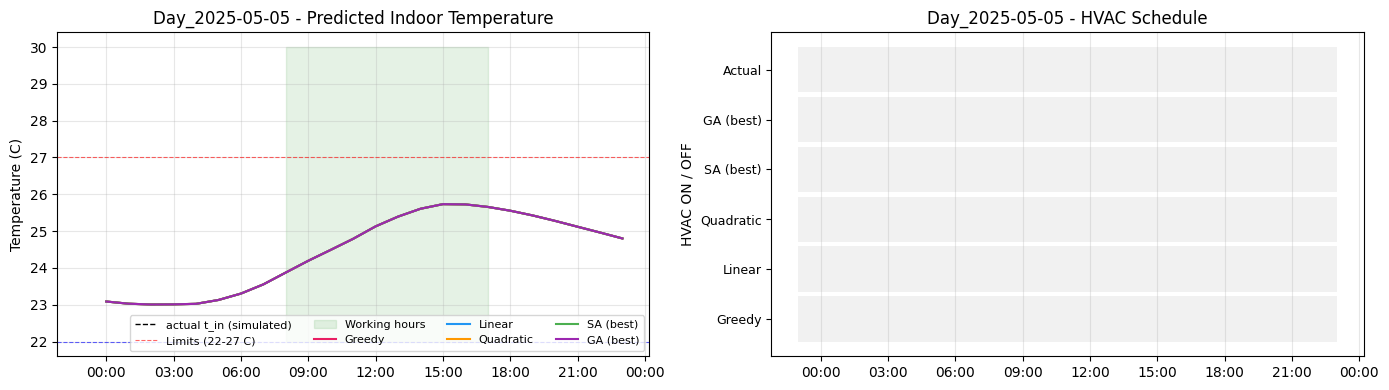

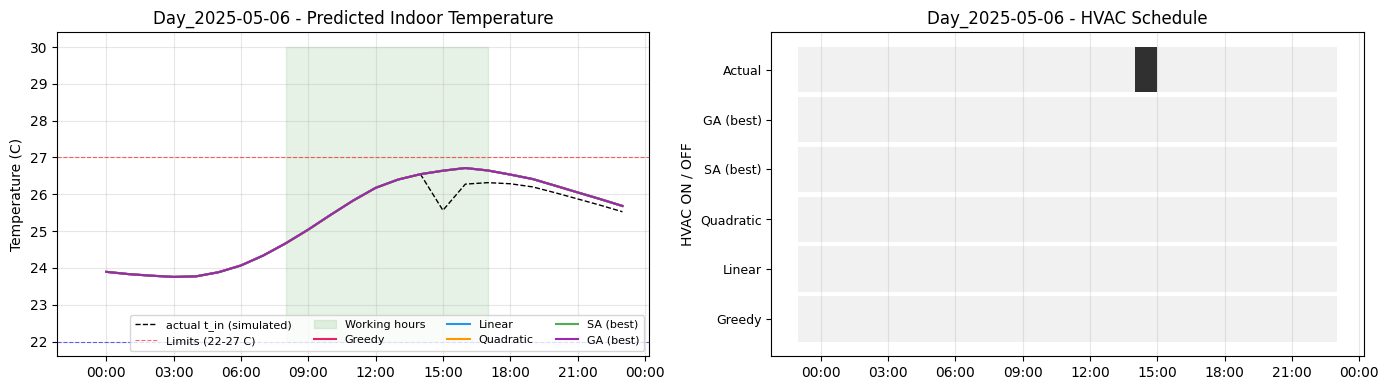

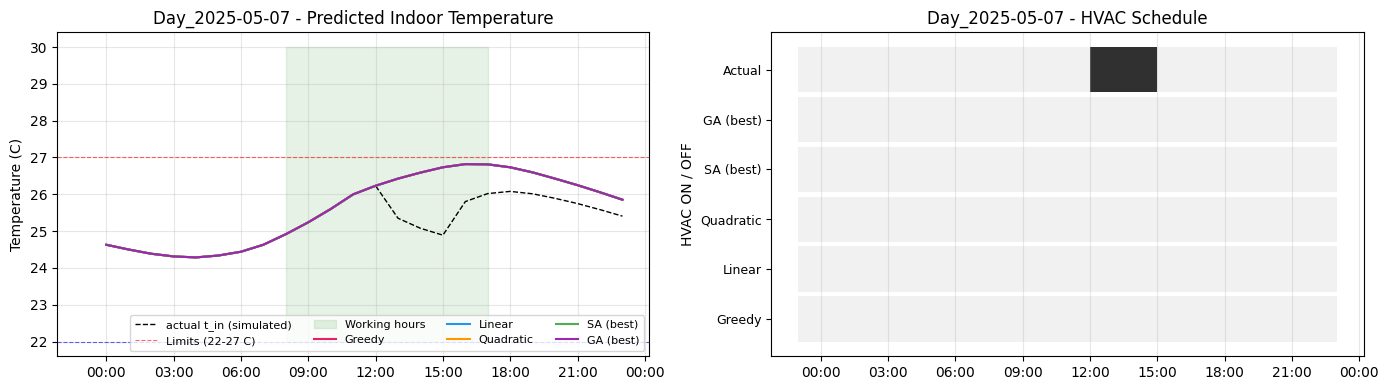

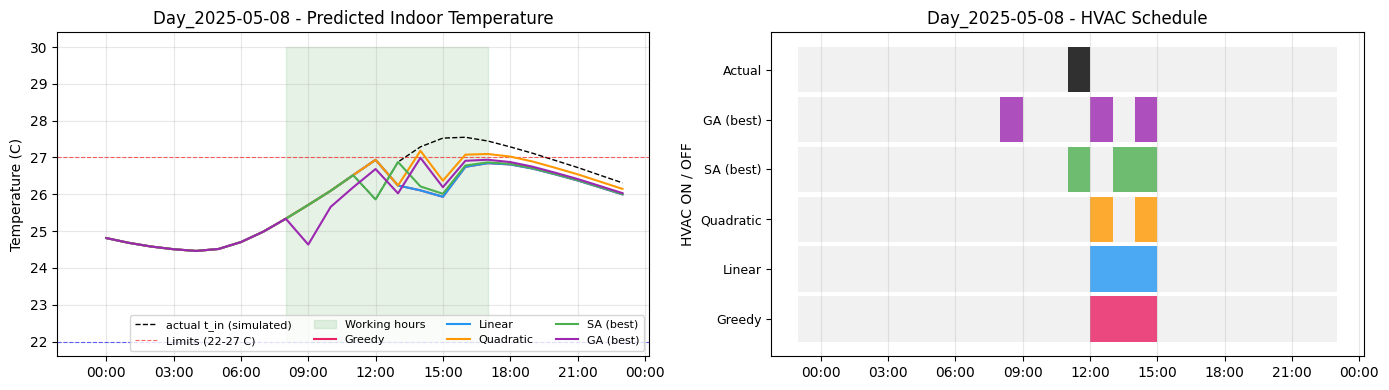

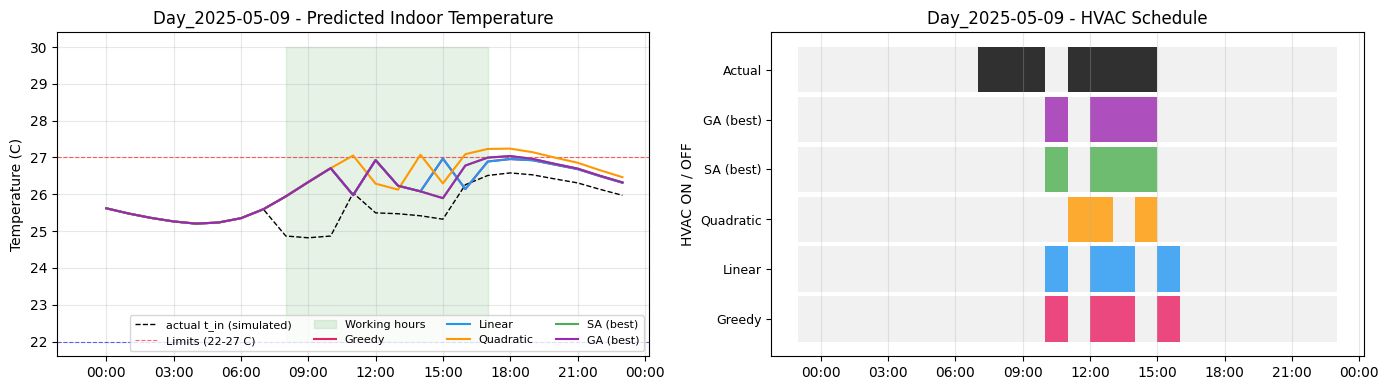

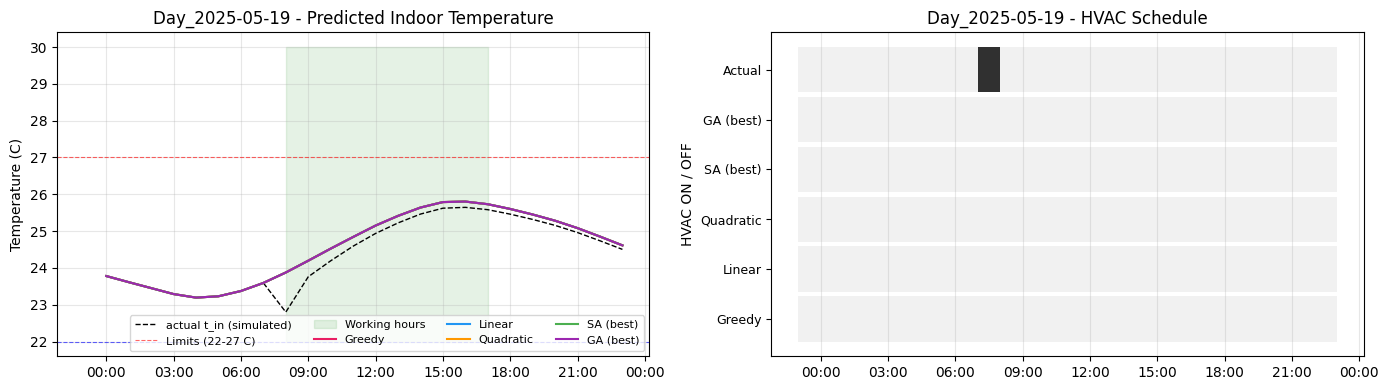

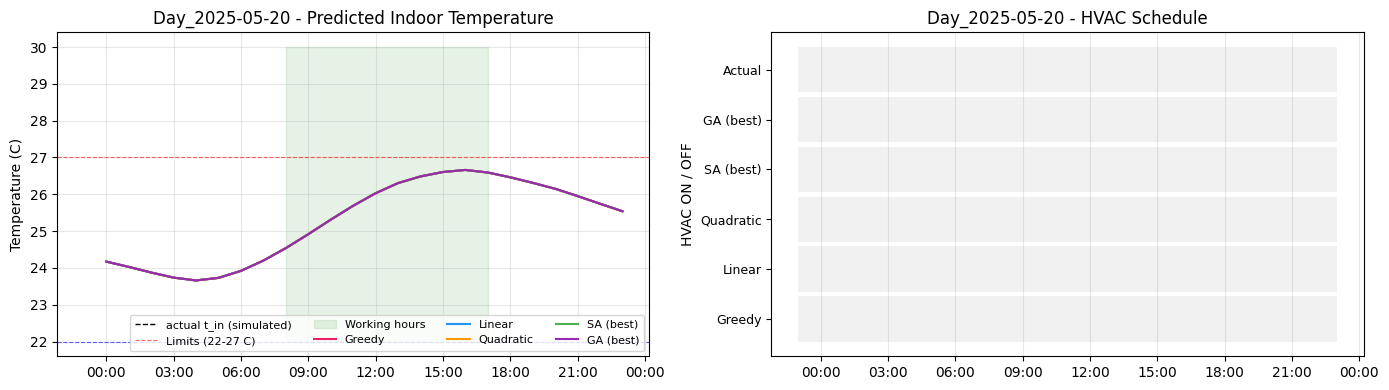

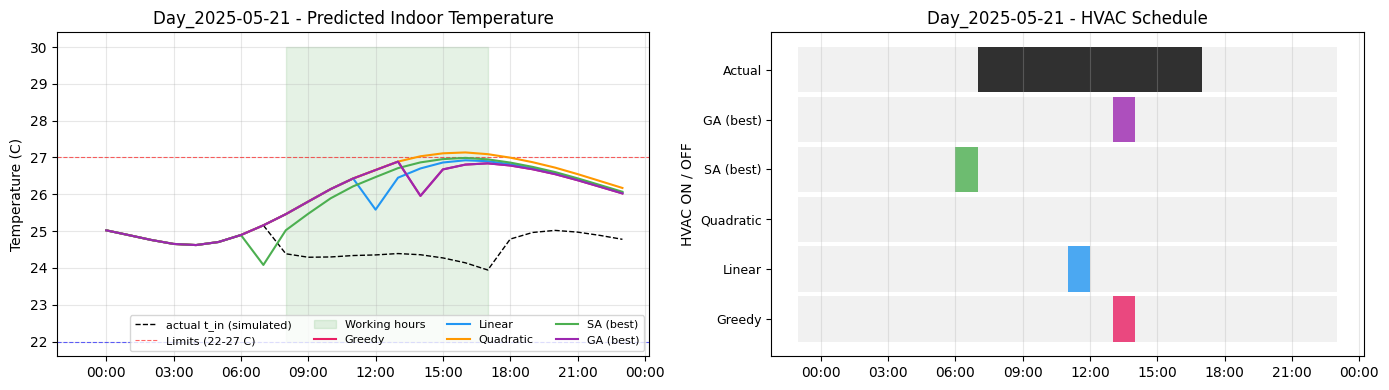

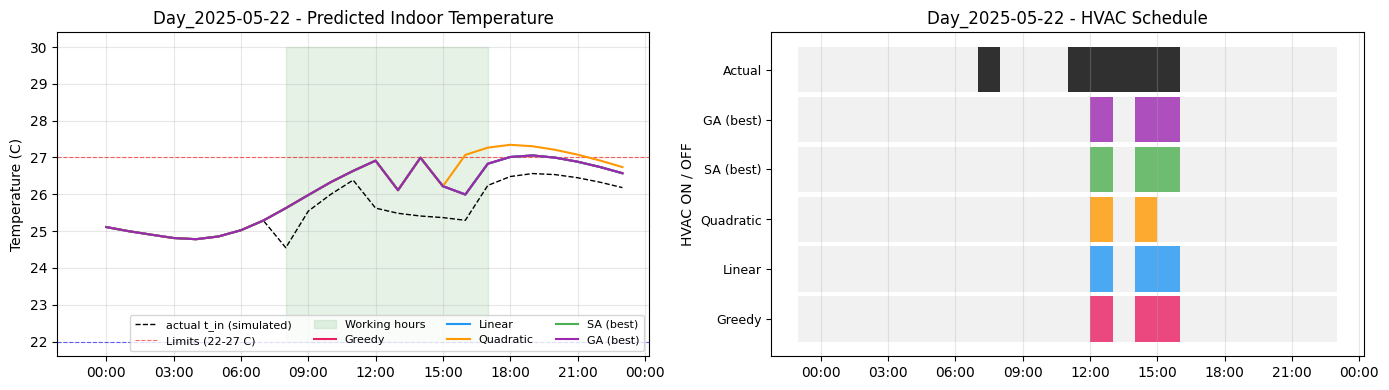

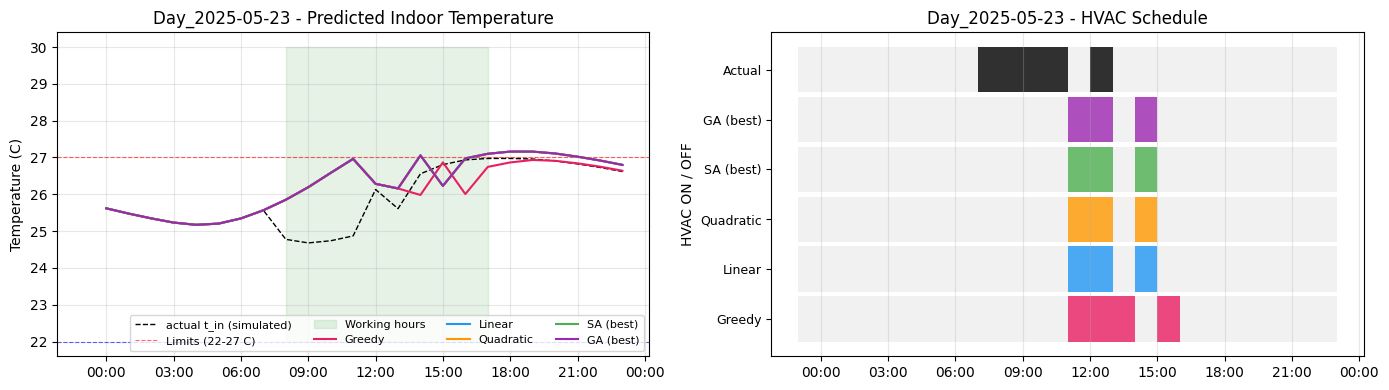

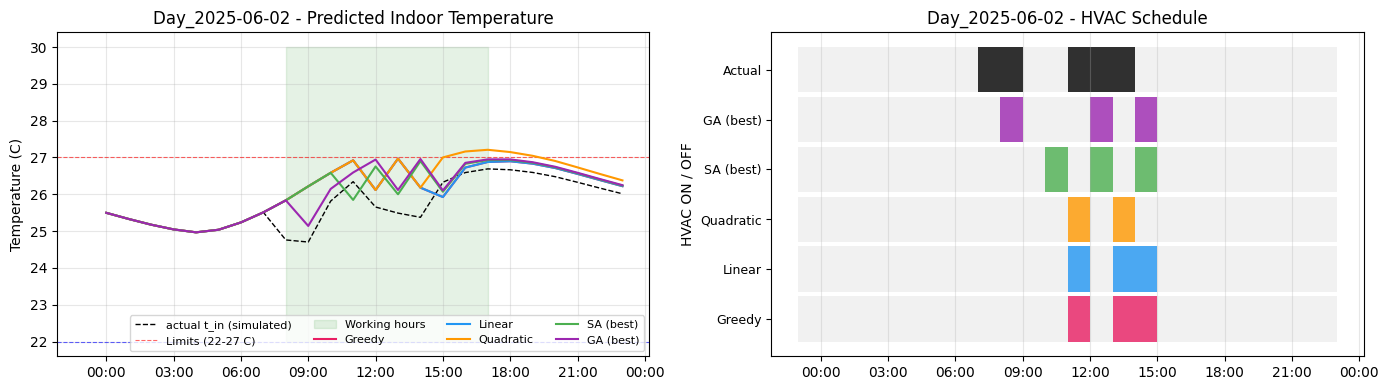

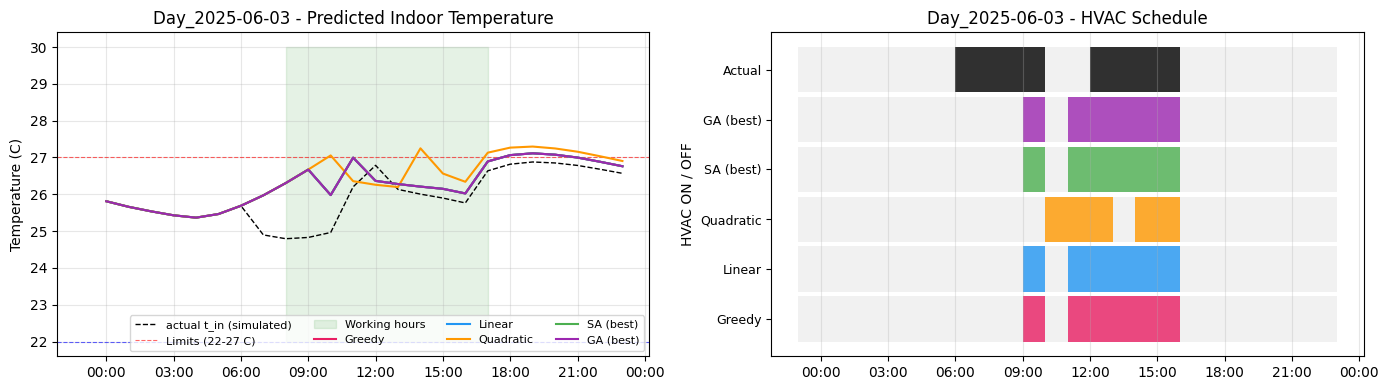

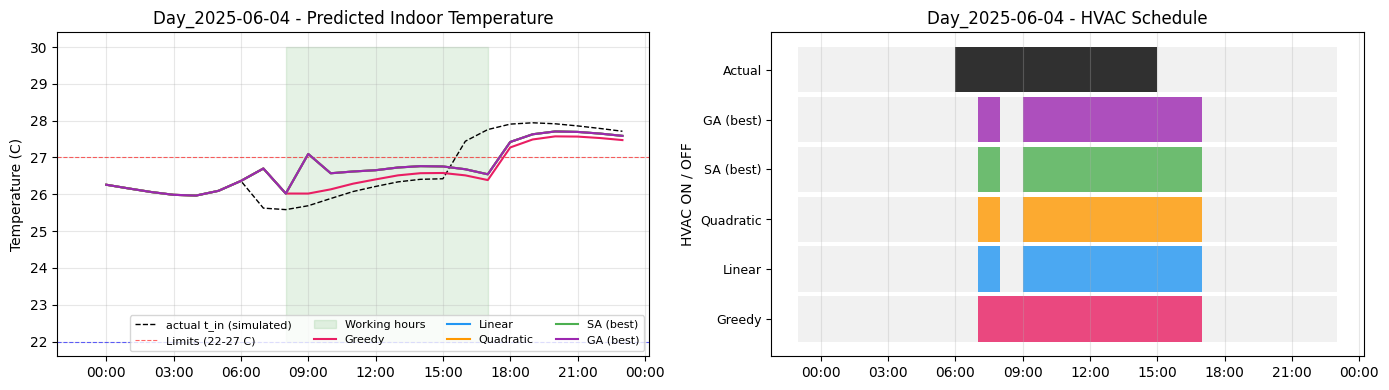

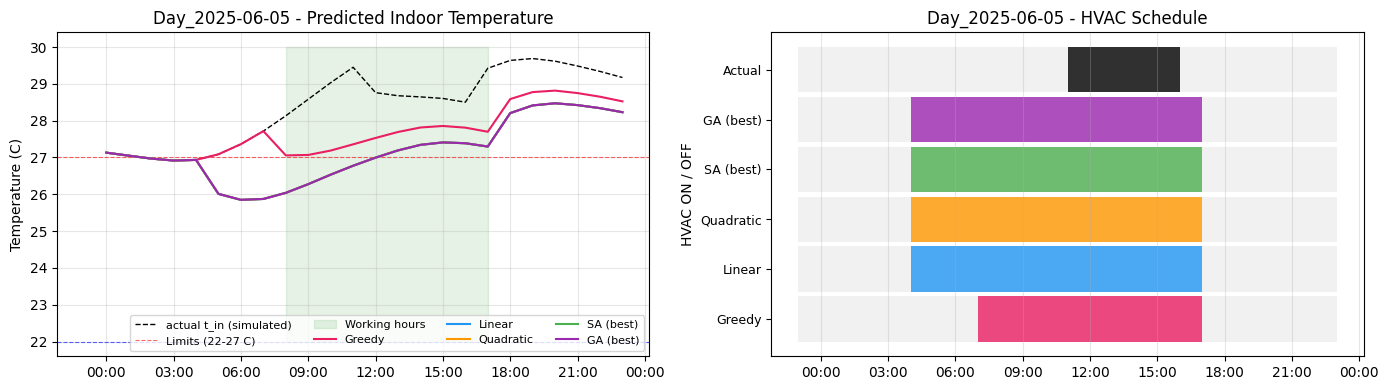

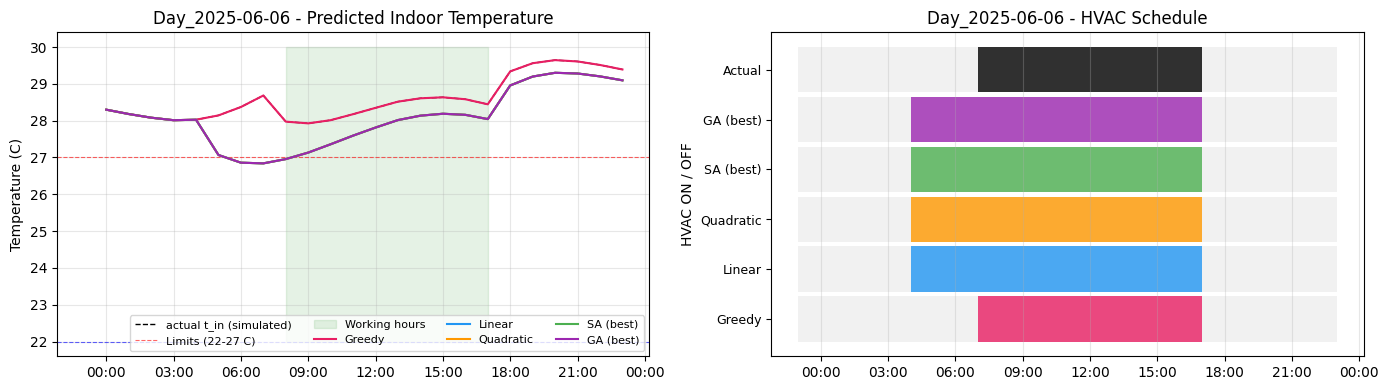

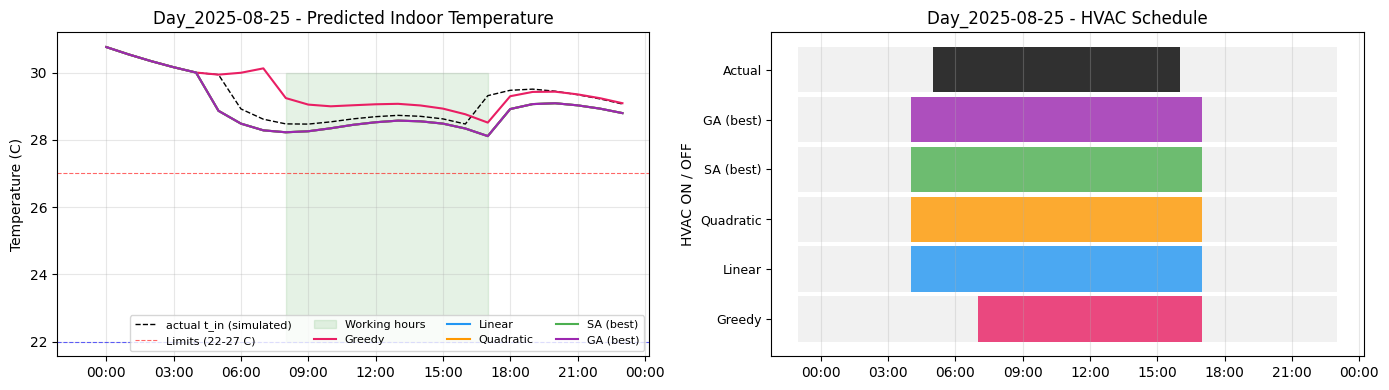

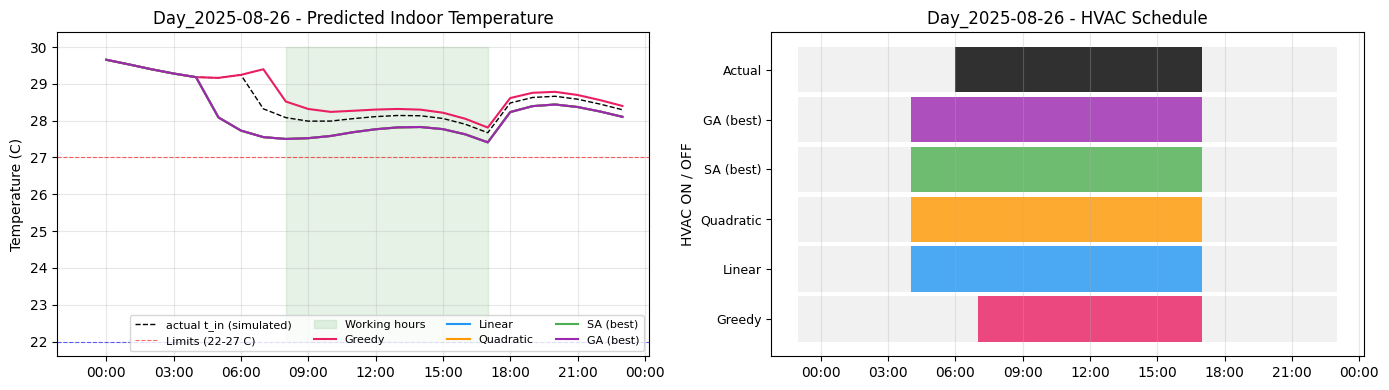

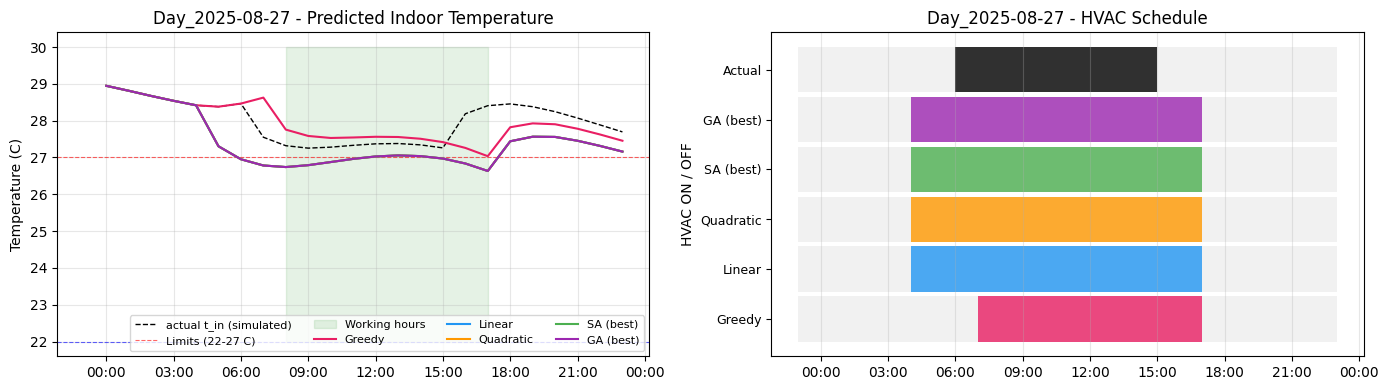

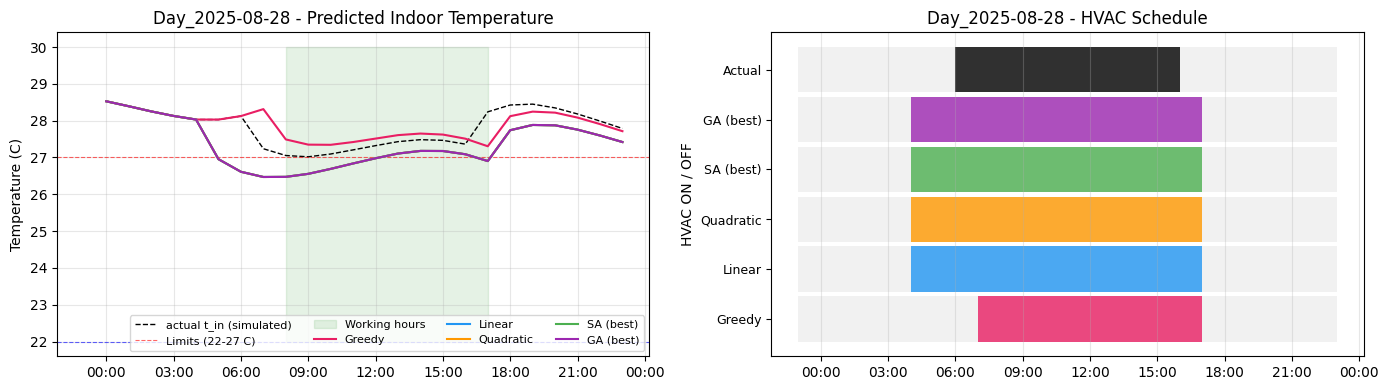

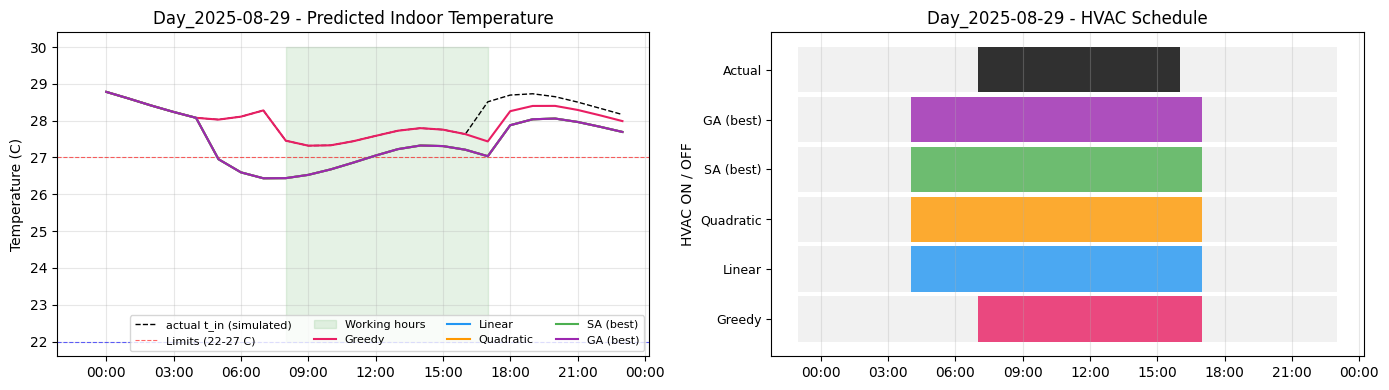

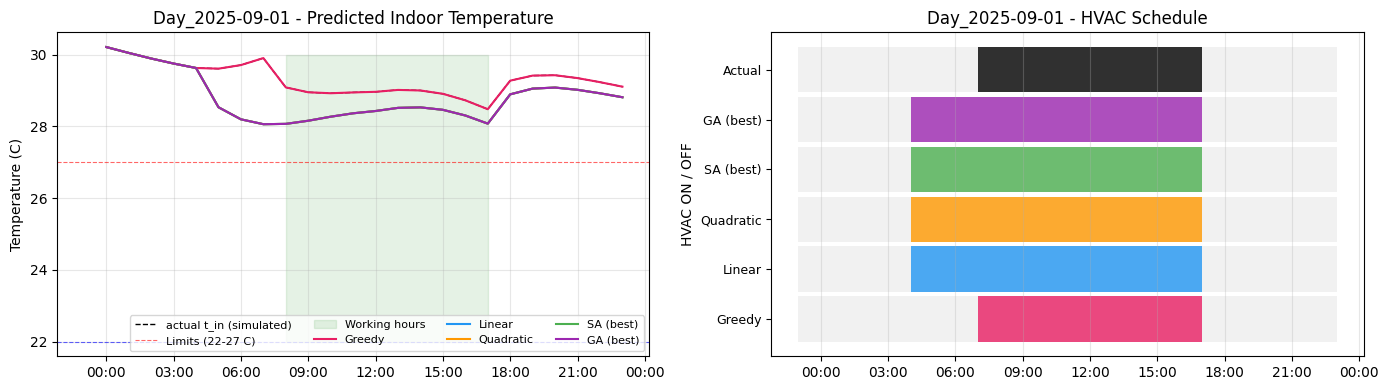

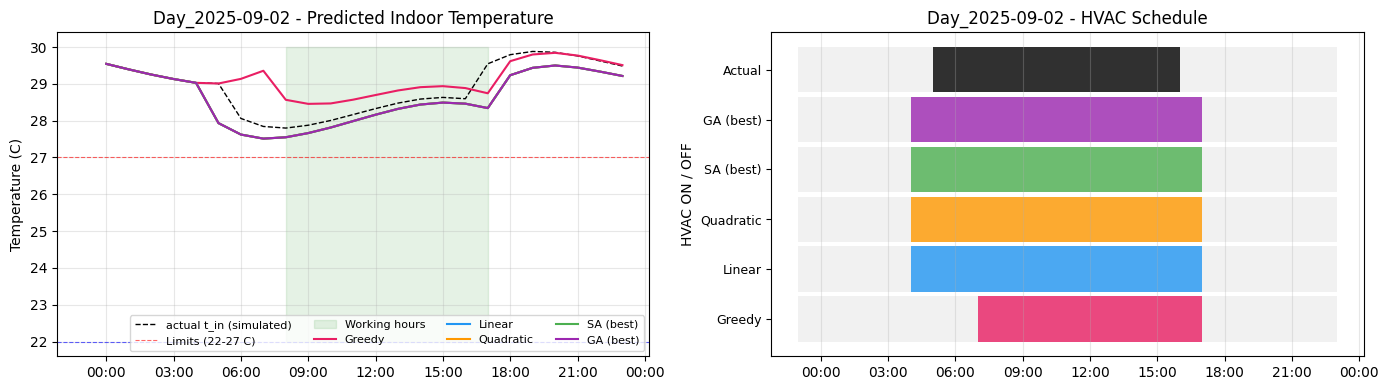

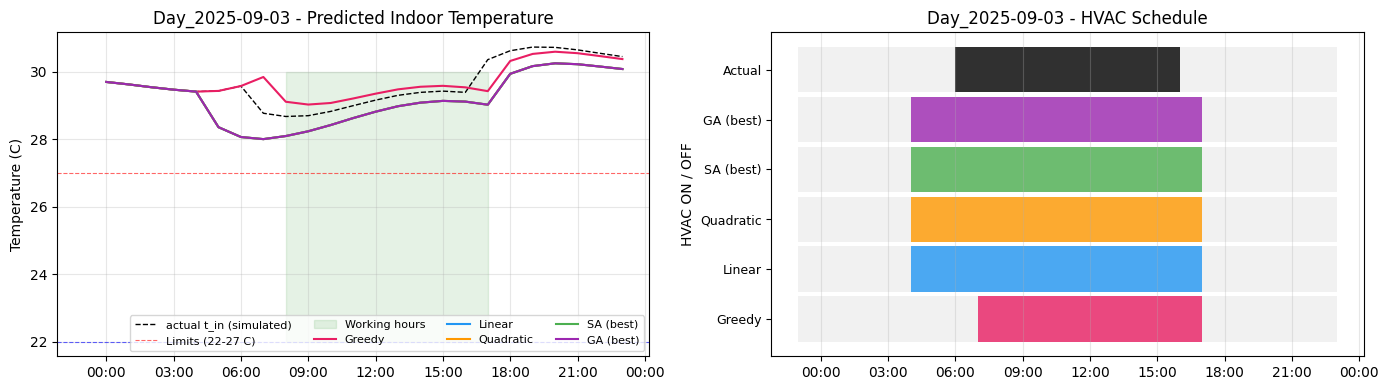

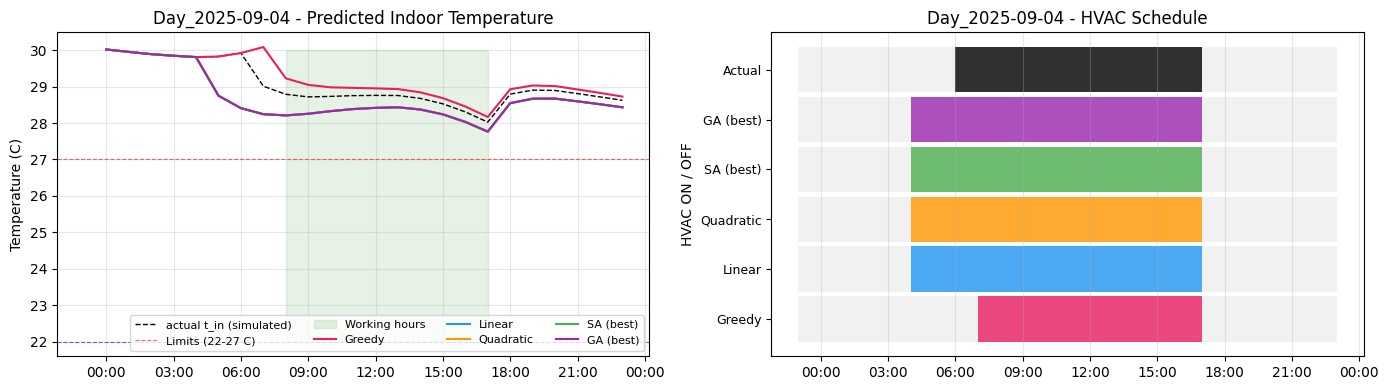

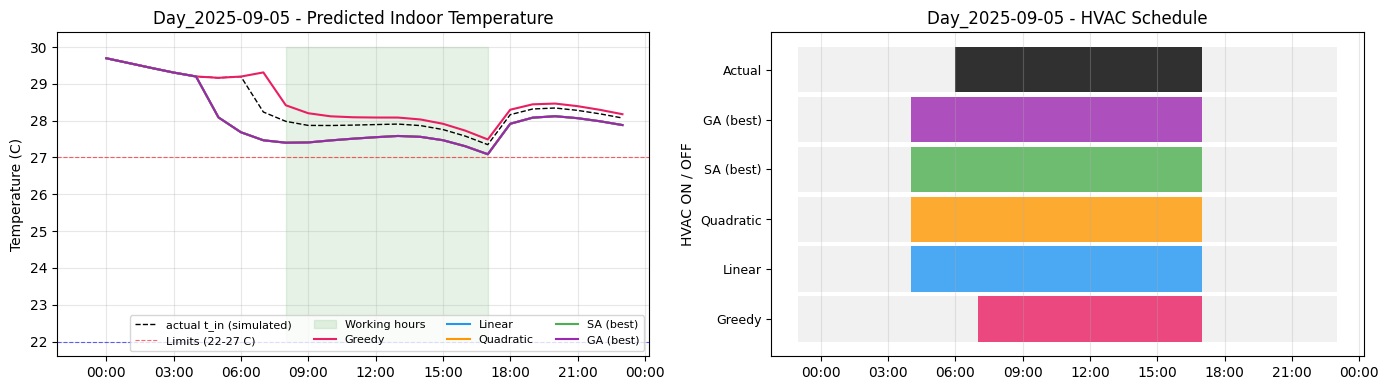

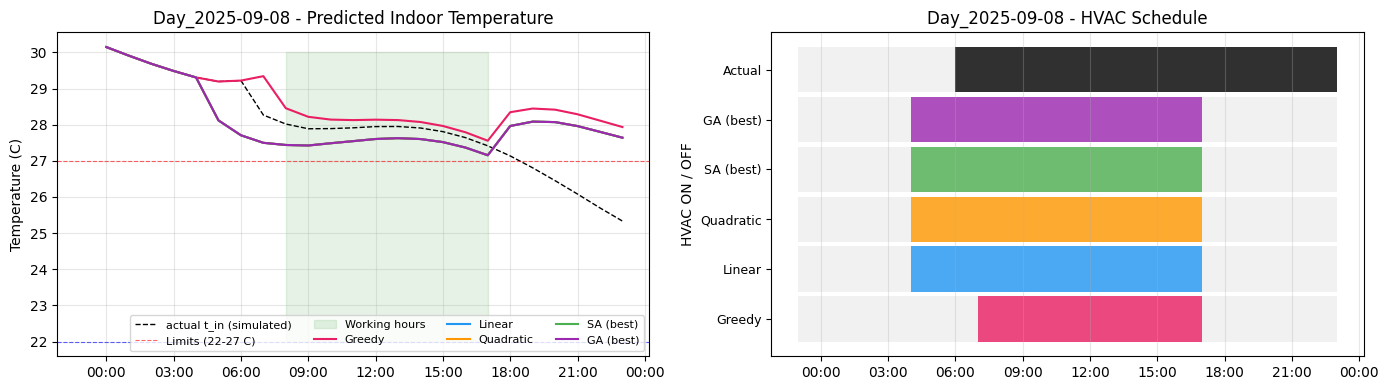

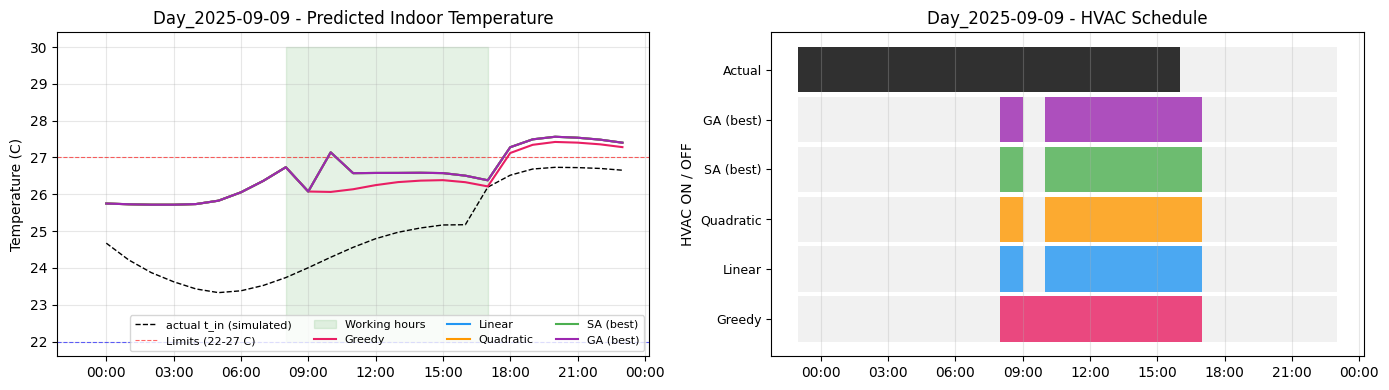

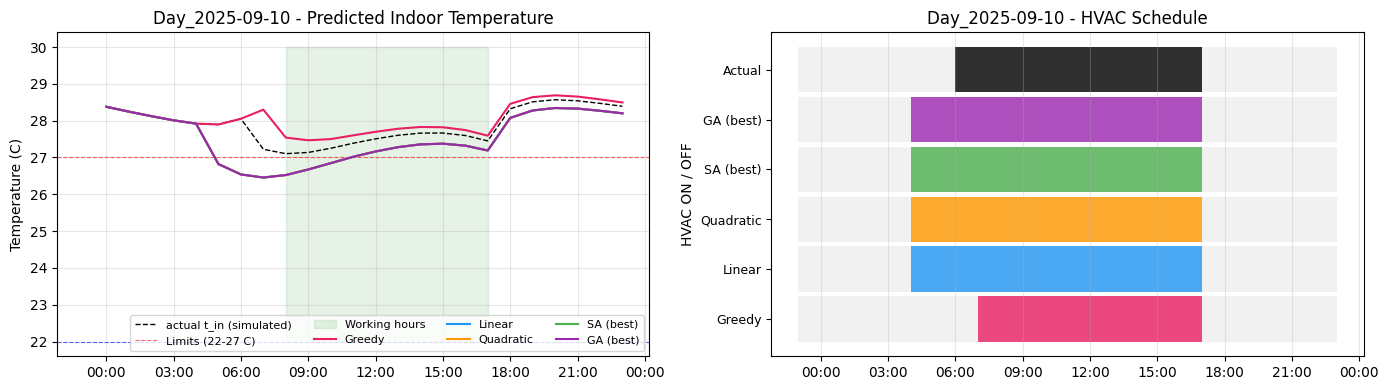

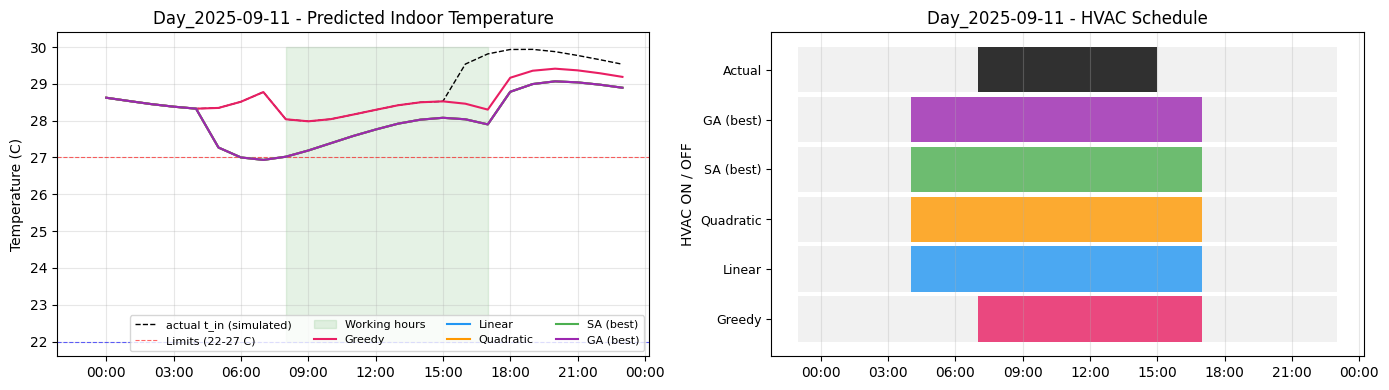

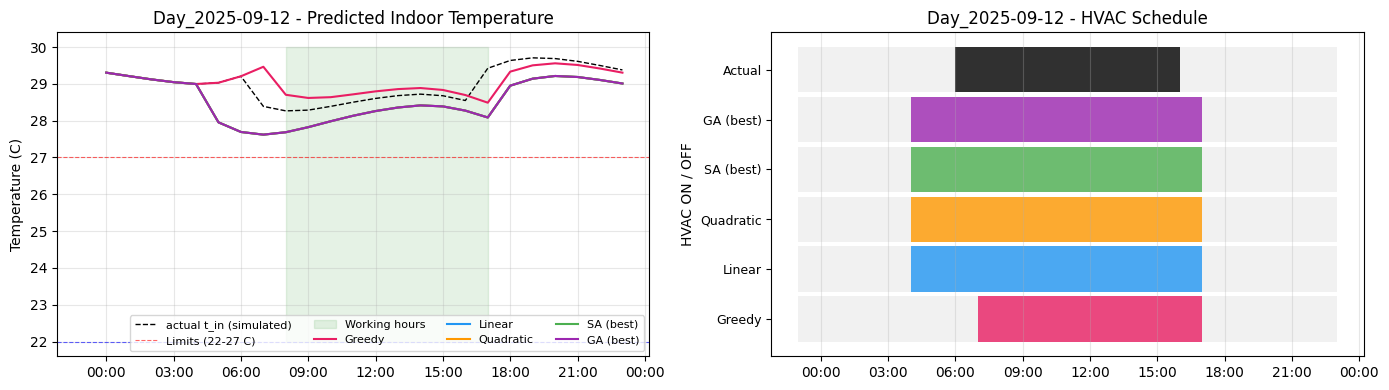

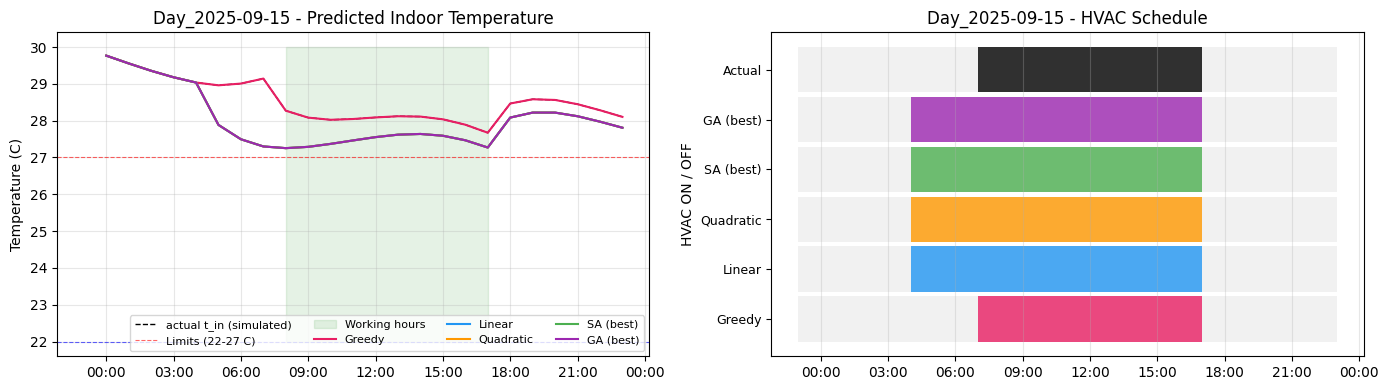

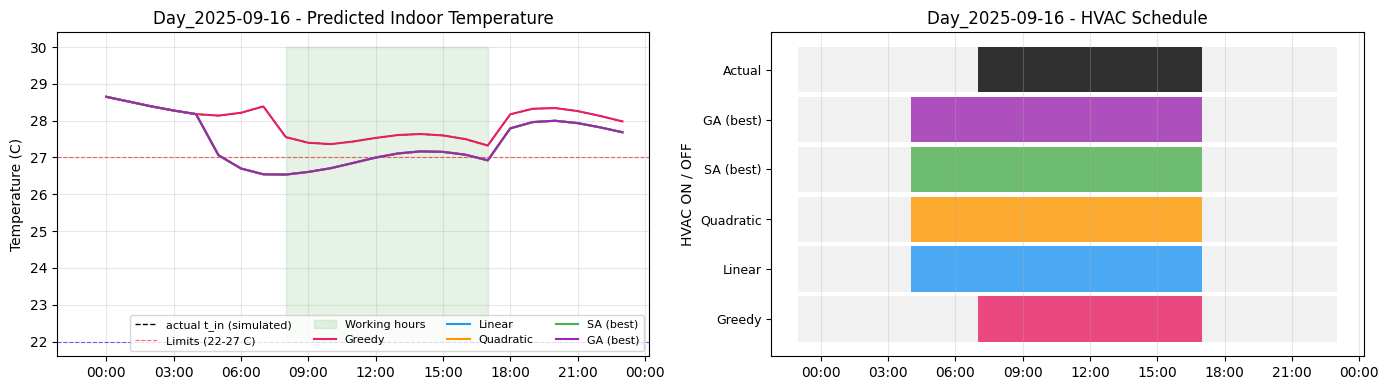

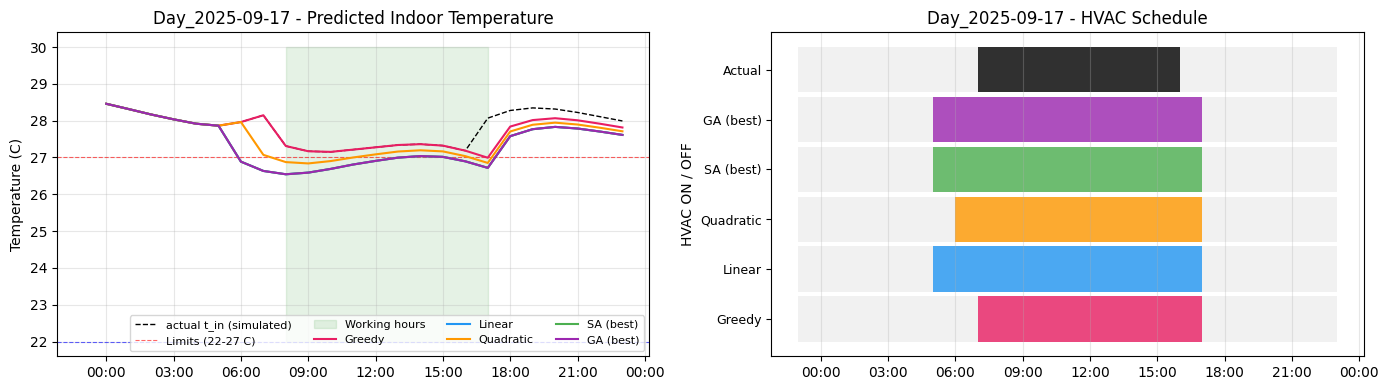

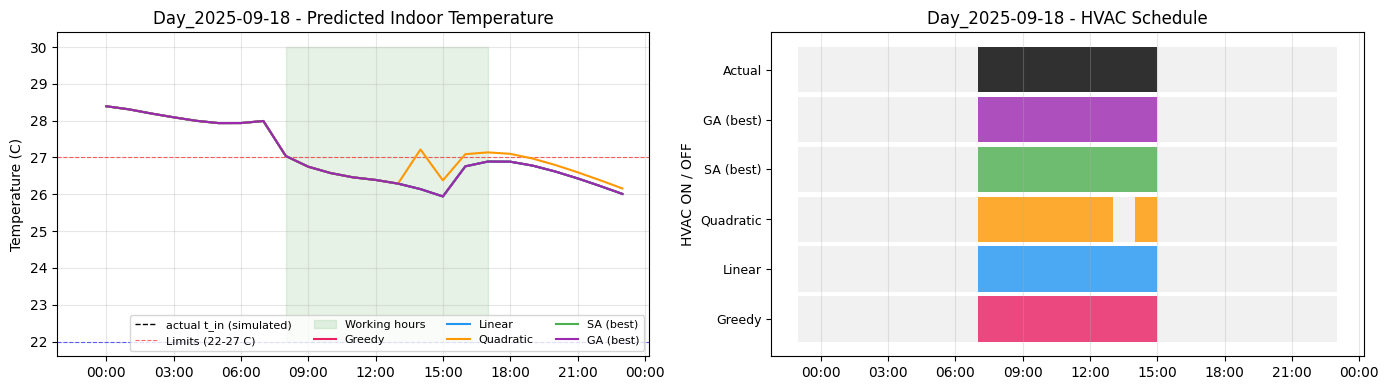

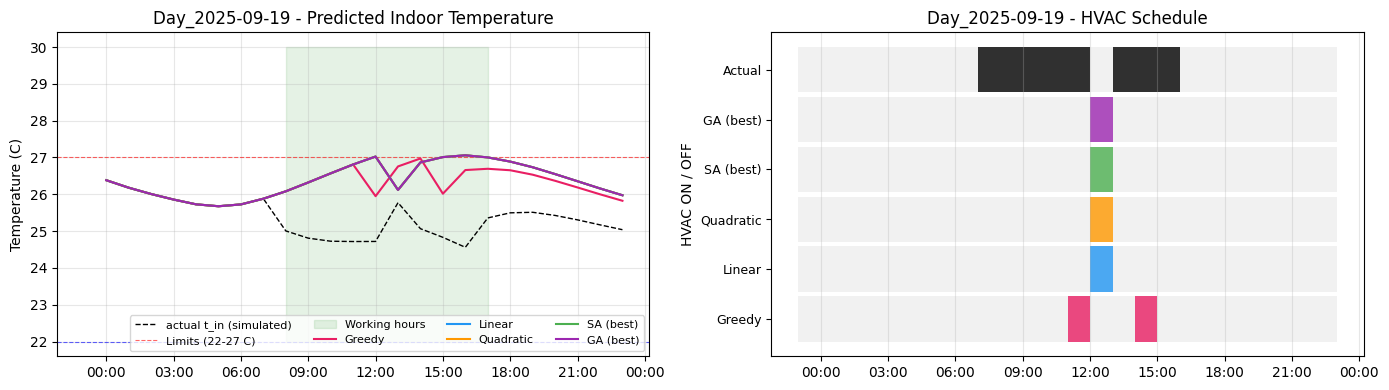

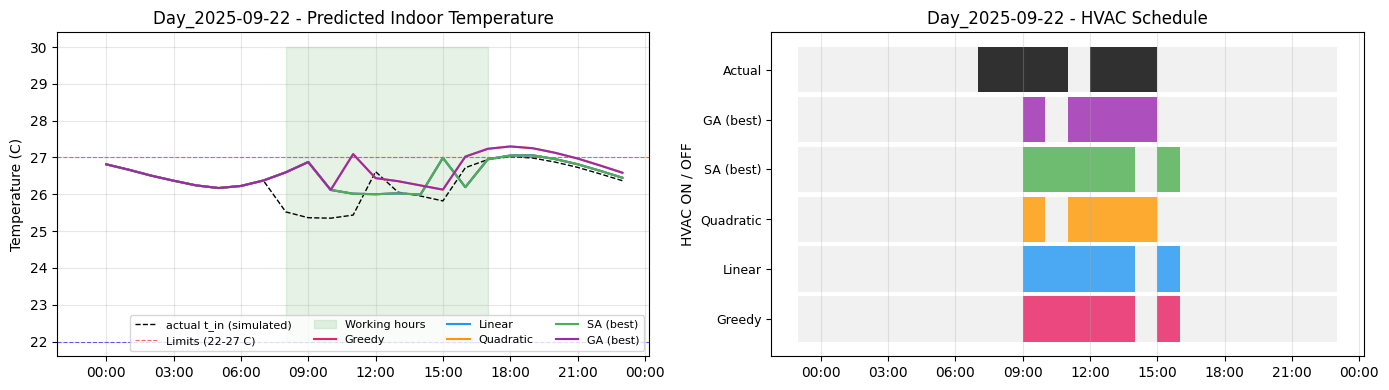

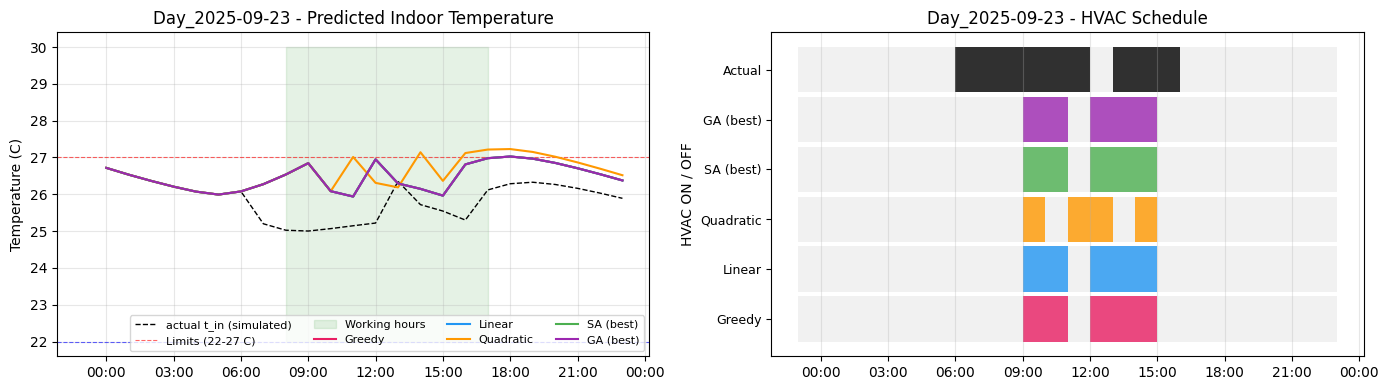

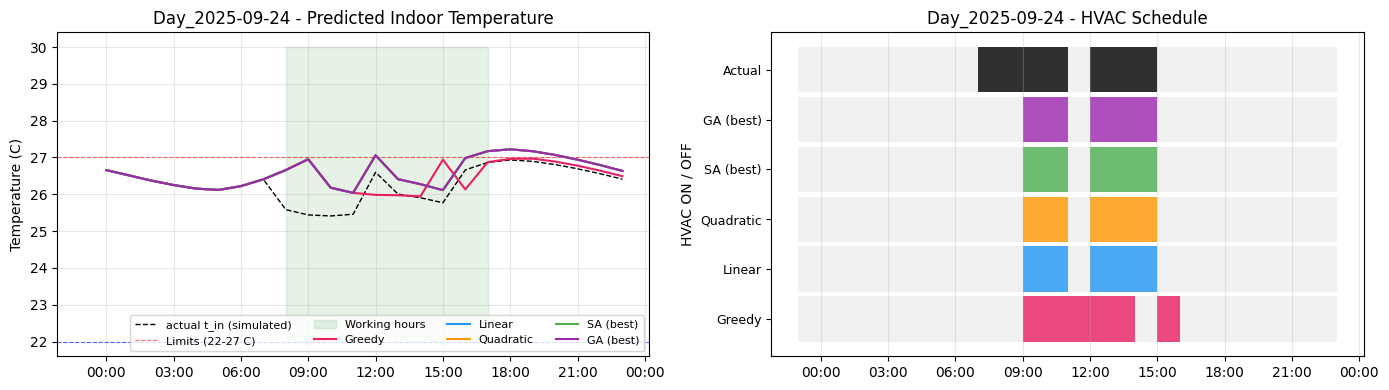

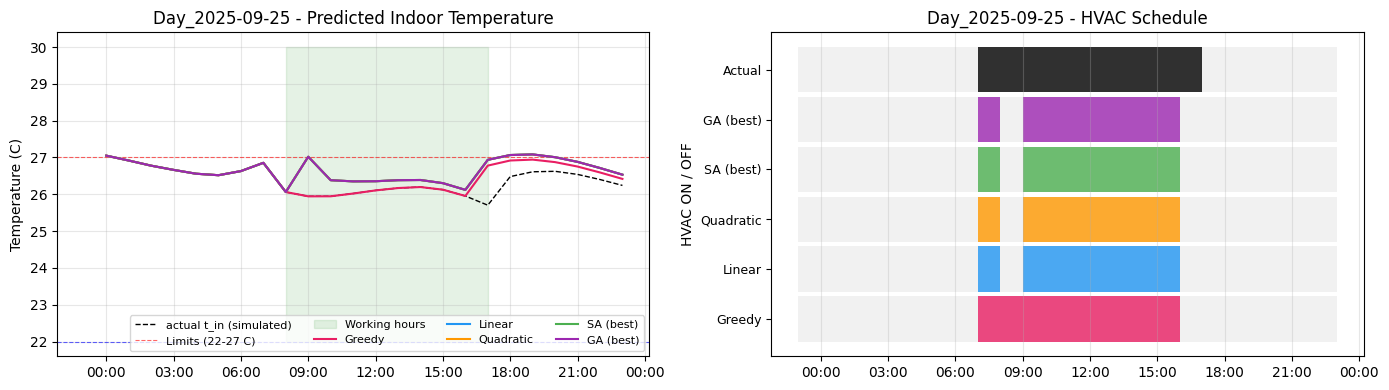

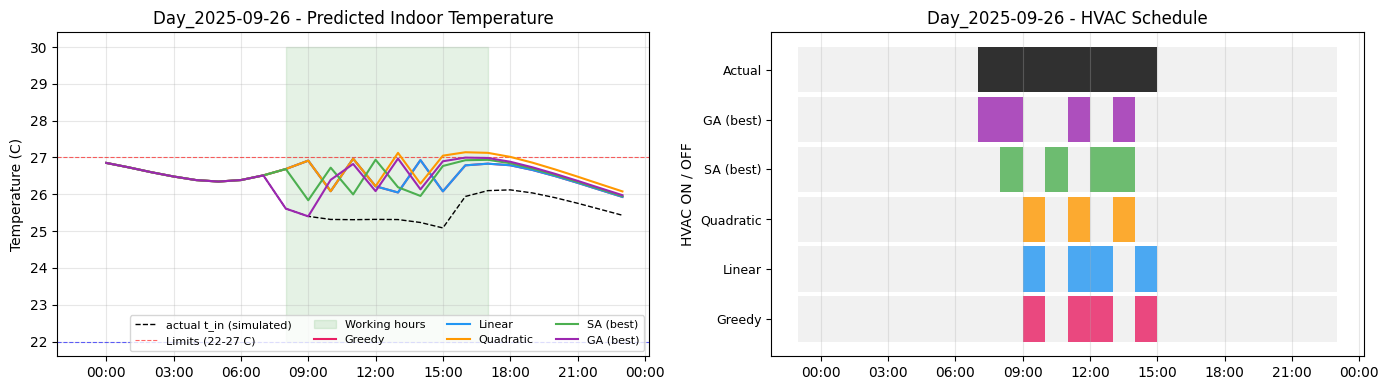

In [ ]:
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
METHOD_COLORS = {
    'Greedy':    '#E91E63',
    'Linear':    '#2196F3',
    'Quadratic': '#FF9800',
    'SA':        '#4CAF50',
    'GA':        '#9C27B0',
}

for label, df in all_session_results.items():
    fig, (ax_temp, ax_sched) = plt.subplots(1, 2, figsize=(14, 4), sharex=True)

    #ax_temp.plot(df.index, df['t_out'], color='orange', lw=1, alpha=0.6, label='t_out')
    ax_temp.plot(df.index, df['actual_t_in'], 'k--', lw=1, alpha=1, label='actual t_in (simulated)')
    ax_temp.axhline(UPPER_LIMIT, color='red',  linestyle='--', lw=0.8, alpha=0.6,
                    label=f'Limits ({LOWER_LIMIT}-{UPPER_LIMIT} C)')
    ax_temp.axhline(LOWER_LIMIT, color='blue', linestyle='--', lw=0.8, alpha=0.6)
    ax_temp.fill_between(df.index, LOWER_LIMIT, UPPER_LIMIT+3, where=df['is_working_hours'],
                         color='green', alpha=0.1, label='Working hours')

    for name, _ in METHODS:
        col = f'{name}_t_in_pred'
        if col in df and df[col].notna().any():
            ax_temp.plot(df.index, df[col], lw=1.5, color=METHOD_COLORS[name],
                         label=METHOD_DISPLAY_NAME.get(name, name))

    ax_temp.set_ylabel('Temperature (C)')
    ax_temp.set_title(f'{label} - Predicted Indoor Temperature')
    ax_temp.legend(fontsize=8, ncol=4, loc='lower right')
    ax_temp.grid(alpha=0.3)

    offsets = {name: i * 1.1 for i, (name, _) in enumerate(METHODS)}
    offsets['Actual'] = len(METHODS) * 1.1

    def _lighten(color, amount=0.55):
        """
        Heating hours in a lighter tint and cooling hours in the normal tone
        """
        r, g, b = mcolors.to_rgb(color)
        return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)

    def draw_schedule_row(ax, idx, heat_mask, cool_mask, y_off, color, row_label):
        """
        Draw one HVAC row as independent 1-hour-wide bars. 
        A mark at timestamp t represents the hour interval ending at t.
        """
        hour_width = 1.0 / 24.0
        day_start  = mdates.date2num(idx[0]) - hour_width
        day_end    = mdates.date2num(idx[-1])
        ax.broken_barh([(day_start, day_end - day_start)], (y_off, 1.0),
                        facecolors='lightgrey', alpha=0.3)

        heat_starts = mdates.date2num(idx[heat_mask]) - hour_width
        if len(heat_starts) > 0:
            ax.broken_barh([(s, hour_width) for s in heat_starts], (y_off, 1.0),
                            facecolors=_lighten(color), alpha=0.8, label=row_label)

        cool_starts = mdates.date2num(idx[cool_mask]) - hour_width
        if len(cool_starts) > 0:
            ax.broken_barh([(s, hour_width) for s in cool_starts], (y_off, 1.0),
                            facecolors=color, alpha=0.8, label=row_label)

    for name, _ in METHODS:
        col = f'{name}_schedule'
        if col in df and df[col].notna().any():
            sched_vals = df[col].fillna(0).values
            draw_schedule_row(ax_sched, df.index, sched_vals == 1, sched_vals == 2, offsets[name],
                               METHOD_COLORS[name], METHOD_DISPLAY_NAME.get(name, name))

    actual_vals = df['actual_schedule'].fillna(0).values
    draw_schedule_row(ax_sched, df.index, actual_vals == 1, actual_vals == 2, offsets['Actual'], 'black', 'Actual')

    ax_sched.set_yticks([v + 0.5 for v in offsets.values()])
    ax_sched.set_yticklabels([METHOD_DISPLAY_NAME.get(k, k) for k in offsets.keys()], fontsize=9)
    ax_sched.set_ylabel('HVAC ON / OFF')
    ax_sched.set_title(f'{label} - HVAC Schedule')
    ax_sched.grid(axis='x', alpha=0.3)

    for ax in (ax_temp, ax_sched):
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

    plt.tight_layout()
    plt.show()

## Cross-Day Summary Table

In [ ]:
for _label, _methods_runs in all_session_stochastic.items():
    _df = all_session_results[_label]
    _milp_sched = _df.get('Linear_schedule')
    if _milp_sched is None or pd.isna(_milp_sched).all():
        continue
    _milp_obj = unified_objective_cost(_milp_sched, _df['Linear_t_in_pred'], _df['is_working_hours'])
    for _method, _runs in _methods_runs.items():
        all_session_robustness.setdefault(_label, {})[_method] = \
            compute_stochastic_robustness(_runs, _milp_sched, _milp_obj)

rows = []
for label, df in all_session_results.items():
    for name, _ in METHODS:
        sched = df.get(f'{name}_schedule')
        if sched is None or sched.isna().all():
            continue
        row = {'Session': label, 'Method': name}
        row.update(compute_method_metrics(df, name, label))
        if name in ('SA', 'GA'):
            row.update(all_session_robustness.get(label, {}).get(name, {}))
        rows.append(row)

    actual_row = {'Session': label, 'Method': 'Actual'}
    actual_row.update(compute_method_metrics(
        df, 'Actual', label,
        schedule_col='actual_schedule', temp_col='actual_t_in',
        real_consumption=df['actual_consumption'].sum(),
    ))
    rows.append(actual_row)

summary_df = pd.DataFrame(rows)

for metric_name in ['HVAC Hours', 'Switches', 'Avg T_in (work)', 'Avg PMV (work)', 'Comfort Violation Hours',
                     'Avg Discomfort (all work hrs)', 'Avg Discomfort (violated hrs)',
                     'Energy Proxy (kWh)', 'Objective Cost', 'Runtime (s)']:
    print(f"=== {metric_name} ===")
    _pivot = summary_df.pivot(index='Session', columns='Method', values=metric_name)
    if metric_name == 'Objective Cost':
        
        _pivot = _pivot.style.format(lambda v: f'{v:.2f}' if isinstance(v, (int, float, np.number)) and not pd.isna(v) else v)
    display(_pivot)
    print()

c:\Users\yiann\AppData\Local\Programs\Python\Python314\Lib\site-packages\pythermalcomfort\models\pmv_ppd_iso.py:181: UserWarning: 'tdb' has 1 value [30.364968010537325] at indices [9] outside the applicability limits [10.0, 30.0] and will be set to NaN.
  tdb_valid = valid_range(tdb, (10.0, 30.0))


=== HVAC Hours ===


Method,Actual,GA,Greedy,Linear,Quadratic,SA
Session,,,,,,
Day_2025-05-05,0,0,0,0,0,0
Day_2025-05-06,1,0,0,0,0,0
Day_2025-05-07,3,0,0,0,0,0
Day_2025-05-08,1,3,3,3,2,3
Day_2025-05-09,7,4,4,4,3,4
Day_2025-05-19,1,0,0,0,0,0
Day_2025-05-20,0,0,0,0,0,0
Day_2025-05-21,10,1,1,1,0,1
Day_2025-05-22,6,3,3,3,2,3



=== Switches ===


Method,Actual,GA,Greedy,Linear,Quadratic,SA
Session,,,,,,
Day_2025-05-05,0,0,0,0,0,0
Day_2025-05-06,2,0,0,0,0,0
Day_2025-05-07,2,0,0,0,0,0
Day_2025-05-08,2,6,2,2,4,4
Day_2025-05-09,4,4,6,6,4,4
Day_2025-05-19,2,0,0,0,0,0
Day_2025-05-20,0,0,0,0,0,0
Day_2025-05-21,2,2,2,2,0,2
Day_2025-05-22,4,4,4,4,4,4



=== Avg T_in (work) ===


... (11 outputs left out)


=== Objective Cost ===


Method,Actual,GA,Greedy,Linear,Quadratic,SA
Session,,,,,,
Day_2025-05-05,0.00,0.00,0.00,0.00,0.00,0.00
Day_2025-05-06,1.00,0.00,0.00,0.00,0.00,0.00
Day_2025-05-07,3.00,0.00,0.00,0.00,0.00,0.00
Day_2025-05-08,6.44,3.00,3.00,3.00,3.06,3.00
Day_2025-05-09,7.00,4.00,4.00,4.00,4.35,4.00
Day_2025-05-19,1.00,0.00,0.00,0.00,0.00,0.00
Day_2025-05-20,0.00,0.00,0.00,0.00,0.00,0.00
Day_2025-05-21,10.00,1.00,1.00,1.00,1.12,1.00
Day_2025-05-22,6.00,3.00,3.00,3.00,3.01,3.00



=== Runtime (s) ===


Method,Actual,GA,Greedy,Linear,Quadratic,SA
Session,,,,,,
Day_2025-05-05,N/A,59.19,0.0,0.04,0.03,40.22
Day_2025-05-06,N/A,58.96,0.01,0.03,0.03,68.6
Day_2025-05-07,N/A,58.35,0.0,0.03,0.02,69.27
Day_2025-05-08,N/A,68.93,0.01,0.07,0.07,71.25
Day_2025-05-09,N/A,72.86,0.0,0.07,0.06,76.14
Day_2025-05-19,N/A,63.34,0.01,0.04,0.03,63.18
Day_2025-05-20,N/A,57.35,0.01,0.04,0.03,69.62
Day_2025-05-21,N/A,52.58,0.0,0.05,0.03,71.62
Day_2025-05-22,N/A,77.45,0.0,0.06,0.05,74.38


## Aggregated Method Comparison (All Test Days)

In [ ]:
# One row per metric, methods as columns, aggregated across every test day.
_num = lambda s: pd.to_numeric(s, errors='coerce')

def _fmt_agg(method, col, how, ndigits):
    s = _num(summary_df.loc[summary_df['Method'] == method, col])
    if s.isna().all():
        return 'N/A'
    val = getattr(s, how)()
    return int(round(val)) if ndigits == 0 else round(float(val), ndigits)

AGG_SPEC = [
    ('HVAC Hours',                    'sum',  'HVAC ON Hours (Total)',                    0),
    ('HVAC Hours',                    'mean', 'Avg HVAC ON Hours (per day)',               2),
    ('Switches',                      'sum',  'Switches (Total)',                      0),
    ('Avg T_in (work)',               'mean', 'Avg T_in (work)',                        2),
    ('Max T_in (work)','mean', 'Avg Max T_in (work)',                                   2),
    ('Comfort Violation Hours',       'sum',  'Comfort Violation Hours (Total)',        0),
    ('Comfort Violation Hours',       'mean', 'Avg Comfort Violation Hours (per day)',  2),
    ('Avg Discomfort (all work hrs)', 'mean', 'Avg Discomfort (all work hrs)',           3),
    ('Avg PMV (work)',                'mean', 'Avg PMV (work)',                         2),
    ('Avg |PMV| (work)',              'mean', 'Avg |PMV| (work)',                       3),
    ('Energy Proxy (kWh)',            'sum',  'Energy Proxy (kWh) (Total)',              2),
    ('Objective Cost',                'sum',  'Objective Cost (Total)',                  2),
    ('Runtime (s)',                   'mean', 'Avg Runtime (s) (per day)',               2),
]

method_order = [m[0] for m in METHODS] + ['Actual']
method_summary_table = pd.DataFrame({
    method: {label: _fmt_agg(method, col, how, nd) for col, how, label, nd in AGG_SPEC}
    for method in method_order
})

n_days_used = summary_df['Session'].nunique()
print(f"=== Method summary, aggregated across {n_days_used} test days ===")
display(method_summary_table)


=== Method summary, aggregated across 40 test days ===


,Greedy,Linear,Quadratic,SA,GA,Actual
HVAC ON Hours (Total),273.000,323.000,312.000,323.000,322.000,323
Avg HVAC ON Hours (per day),6.830,8.070,7.800,8.070,8.050,8.07
Switches (Total),94.000,98.000,100.000,100.000,102.000,92
Avg T_in (work),27.130,26.890,26.950,26.890,26.890,26.81
Avg Max T_in (work),27.550,27.330,27.390,27.330,27.340,27.52
Comfort Violation Hours (Total),190.000,162.000,199.000,162.000,165.000,197
Avg Comfort Violation Hours (per day),4.750,4.050,4.970,4.050,4.120,4.92
Avg Discomfort (all work hrs),0.545,0.302,0.313,0.302,0.303,0.546
Avg PMV (work),0.730,0.650,0.670,0.650,0.650,0.61
Avg |PMV| (work),0.732,0.659,0.676,0.657,0.658,0.632


In [ ]:
# Robustness of the stochastic methods (SA, GA), computed over independent runs of each day 
ROBUST_SPEC = [
    ('mean_objective',   'mean', f'Mean Objective Cost (all {N_STOCHASTIC_RUNS} runs, per day)', 3),
    ('success_rate_pct', 'mean', 'Success Rate vs MILP schedule (%)',                            3),
    ('objective_match_rate_pct', 'mean', 'Success Rate vs MILP objective (%)',                   3),
    ('mean_gap',         'mean', 'Mean Objective Gap vs MILP (obj. units)',                      3),
    ('median_gap',       'mean', 'Median Objective Gap vs MILP (obj. units)',                    3),
    ('std_gap',          'mean', 'Std of Objective Gap (run-to-run, obj. units)',                3),
    ('milp_objective',   'mean', 'MILP Mean Objective Cost (reference, per day)',                3),
]

stochastic_methods = [m for m in ('SA', 'GA') if m in method_order]
stochastic_robustness_table = pd.DataFrame({
    m: {label: _fmt_agg(m, col, how, nd) for col, how, label, nd in ROBUST_SPEC}
    for m in stochastic_methods
})

print(f"=== SA/GA robustness over {N_STOCHASTIC_RUNS} runs per day, aggregated across {n_days_used} test days ===")
display(stochastic_robustness_table)


=== SA/GA robustness over 10 runs per day, aggregated across 40 test days ===


,SA,GA
"Mean Objective Cost (all 10 runs, per day)",17.169,17.324
Success Rate vs MILP schedule (%),71.750,65.500
Success Rate vs MILP objective (%),79.750,72.500
Mean Objective Gap vs MILP (obj. units),0.041,0.196
Median Objective Gap vs MILP (obj. units),0.030,0.050
"Std of Objective Gap (run-to-run, obj. units)",0.044,0.421
"MILP Mean Objective Cost (reference, per day)",17.128,17.128


### Trade-off Scatter: HVAC ON Hours vs Comfort (5 Methods)

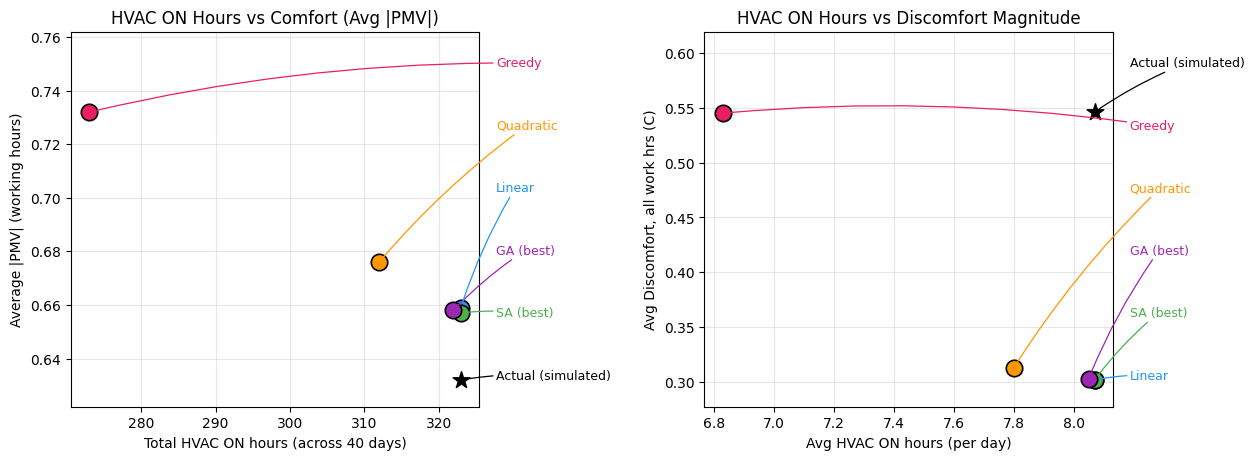

   method  hours_total  avg_abs_pmv  dominated
   Greedy        273.0        0.732      False
   Linear        323.0        0.659       True
Quadratic        312.0        0.676      False
       SA        323.0        0.657      False
       GA        322.0        0.658      False

   method  avg_hours_per_day  avg_discomfort  dominated
   Greedy               6.83           0.545      False
   Linear               8.07           0.302      False
Quadratic               7.80           0.313      False
       SA               8.07           0.302      False
       GA               8.05           0.303      False


In [ ]:
# Two trade-off scatters, side by side
def _collect_points(x_row, y_row, methods):
    pts = []
    for method in methods:
        x, y = x_row.get(method), y_row.get(method)
        if x == 'N/A' or y == 'N/A':
            print(f"  skipping {method}: no valid results across the test days")
            continue
        pts.append({'method': method, 'x': float(x), 'y': float(y)})
    return pd.DataFrame(pts)


def _actual_point(x_row, y_row):
    x, y = x_row.get('Actual'), y_row.get('Actual')
    return None if (x == 'N/A' or y == 'N/A') else (float(x), float(y))


def _dominated_mask(df):
    flags = []
    for _, row in df.iterrows():
        dom = any(
            (other['x'] <= row['x']) and (other['y'] <= row['y']) and
            ((other['x'] <  row['x']) or  (other['y'] <  row['y']))
            for _, other in df.iterrows() if other['method'] != row['method']
        )
        flags.append(dom)
    return flags


def _plot_tradeoff(ax, points_df, actual_xy, xlabel, ylabel, title):
    for _, row in points_df.iterrows():
            marker = 'o'
            ax.scatter(row['x'], row['y'], s=140, marker=marker, color=METHOD_COLORS[row['method']],
                       edgecolors='black',
                       linewidths=1.2, zorder=3)
    if actual_xy is not None:
        ax.scatter(actual_xy[0], actual_xy[1], s=160, marker='*', color='black', zorder=3)

    entries = [(METHOD_DISPLAY_NAME.get(row['method'], row['method']), row['x'], row['y'], METHOD_COLORS[row['method']])
               for _, row in points_df.iterrows()]
    if actual_xy is not None:
        entries.append(('Actual (simulated)', actual_xy[0], actual_xy[1], 'black'))
    entries.sort(key=lambda e: e[2])  

    # Headroom above the highest point
    all_y = [e[2] for e in entries]
    y_lo, y_hi = min(all_y), max(all_y)
    y_span = (y_hi - y_lo) or max(abs(y_hi), 1.0)
    ax.set_ylim(y_lo - 0.10 * y_span, y_hi + 0.30 * y_span)

    n = len(entries)
    for i, (name, px, py, color) in enumerate(entries):
        label_y = (i + 0.5) / n
        ax.annotate(
            name,
            xy=(px, py), xycoords='data',
            xytext=(1.04, label_y), textcoords='axes fraction',
            fontsize=9, color=color, va='center', ha='left',
            arrowprops=dict(arrowstyle='-', color=color, lw=0.9, shrinkA=0, shrinkB=4,
                             connectionstyle='arc3,rad=0.06'),
            annotation_clip=False,
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)


method_names = [m[0] for m in METHODS]
n_days_used  = summary_df['Session'].nunique()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Left: Total HVAC ON hours vs Avg |PMV|
hours_total = method_summary_table.loc['HVAC ON Hours (Total)']
abs_pmv     = method_summary_table.loc['Avg |PMV| (work)']
points1 = _collect_points(hours_total, abs_pmv, method_names)
points1['dominated'] = _dominated_mask(points1)
_plot_tradeoff(ax1, points1, _actual_point(hours_total, abs_pmv),
               xlabel=f'Total HVAC ON hours (across {n_days_used} days)',
               ylabel='Average |PMV| (working hours)',
               title='HVAC ON Hours vs Comfort (Avg |PMV|)')

# Right: Avg HVAC ON hours (per day) vs Avg Discomfort (all work hrs, degC)
avg_hours = method_summary_table.loc['Avg HVAC ON Hours (per day)']
avg_disc  = method_summary_table.loc['Avg Discomfort (all work hrs)']
points2 = _collect_points(avg_hours, avg_disc, method_names)
points2['dominated'] = _dominated_mask(points2)
_plot_tradeoff(ax2, points2, _actual_point(avg_hours, avg_disc),
               xlabel='Avg HVAC ON hours (per day)',
               ylabel='Avg Discomfort, all work hrs (C)',
               title='HVAC ON Hours vs Discomfort Magnitude')

fig.subplots_adjust(wspace=0.55, right=0.82, top=0.86)
plt.show()

print(points1[['method', 'x', 'y', 'dominated']].rename(columns={'x': 'hours_total', 'y': 'avg_abs_pmv'}).to_string(index=False))
print()
print(points2[['method', 'x', 'y', 'dominated']].rename(columns={'x': 'avg_hours_per_day', 'y': 'avg_discomfort'}).to_string(index=False))


## Pairwise Schedule Agreement Between Methods

In [ ]:
# Pairwise day-by-day agreement between all 5 methods + Actual.

ACTUAL_SCHEDULE_COL = 'actual_schedule'

def _on_pattern(df, col):
    s = df.get(col)
    if s is None or s.isna().all():
        return None
    # Mode-aware: (0 off / 1 heating / 2 cooling)
    return np.rint(s.fillna(0).astype(float).values).astype(int)

def _objective(df, sched_col, temp_col):
    """Objective Cost (the same unified score used everywhere else) of one source's day."""
    s, t = df.get(sched_col), df.get(temp_col)
    if s is None or t is None or s.isna().all():
        return None
    return unified_objective_cost(s.fillna(0).astype(float), t.astype(float), df['is_working_hours'])

sources = [(name, f'{name}_schedule') for name, _ in METHODS] + [('Actual', ACTUAL_SCHEDULE_COL)]
temp_cols = {**{name: f'{name}_t_in_pred' for name, _ in METHODS}, 'Actual': 'actual_t_in'}
labels = [name for name, _ in sources]

exact_match    = pd.DataFrame(0, index=labels, columns=labels)
same_objective = pd.DataFrame(0, index=labels, columns=labels)
valid_days     = pd.DataFrame(0, index=labels, columns=labels)

# Per-pair lists of the actual differing dates 
exact_diff_days = {}
obj_diff_days = {}

for day, df in all_session_results.items():
    patterns   = {name: _on_pattern(df, col) for name, col in sources}
    objectives = {name: _objective(df, col, temp_cols[name]) for name, col in sources}
    for i, ni in enumerate(labels):
        pi, oi = patterns[ni], objectives[ni]
        if pi is None:
            continue
        for j, nj in enumerate(labels):
            pj, oj = patterns[nj], objectives[nj]
            if pj is None:
                continue
            valid_days.loc[ni, nj] += 1
            identical = np.array_equal(pi, pj)
            if identical:
                exact_match.loc[ni, nj] += 1
            elif j > i:
                exact_diff_days.setdefault((ni, nj), []).append(day)
            # an identical schedule always counts
            if identical or abs(oi - oj) <= OBJECTIVE_MATCH_TOL:
                same_objective.loc[ni, nj] += 1
            elif j > i:
                obj_diff_days.setdefault((ni, nj), []).append((day, oi, oj))

print("=== Exact schedule match (days) ===")
display(exact_match)
print()
print(f"=== Same objective value that day, within +/-{OBJECTIVE_MATCH_TOL:g} (includes exact matches) ===")
display(same_objective)
print()
print("=== Valid comparison days per pair (lower than the full day count means that method failed on some days) ===")
display(valid_days)

print()
print("=== Dates that differ in objective value (per pair; omitted pairs agree on every comparable day) ===")
if not obj_diff_days:
    print("  every pair reached the same objective value on every comparable day")
for (a, b), entries in obj_diff_days.items():
    print(f"  {a} vs {b} ({len(entries)} day(s)):")
    for day, oa, ob in sorted(entries):
        print(f"    {day}: {a}={oa:.4f}, {b}={ob:.4f}  (diff {ob - oa:+.4f})")

print()
print("=== Dates that differ in exact hour-by-hour arrangement (per pair; a day here with the same objective")
print("    value is a tie: an equally good schedule, just at different hours) ===")
if not exact_diff_days:
    print("  every pair matches exactly on every comparable day")
for (a, b), days in exact_diff_days.items():
    obj_diff_dates = {d for d, _, _ in obj_diff_days.get((a, b), [])}
    print(f"  {a} vs {b} ({len(days)} day(s)):")
    for d in sorted(days):
        tag = "also differs in objective value" if d in obj_diff_dates else "same objective value, different arrangement (tie)"
        print(f"    {d} [{tag}]")


=== Exact schedule match (days) ===


,Greedy,Linear,Quadratic,SA,GA,Actual
Greedy,40,14,5,10,10,7
Linear,14,40,29,35,34,3
Quadratic,5,29,40,29,30,2
SA,10,35,29,40,35,3
GA,10,34,30,35,40,3
Actual,7,3,2,3,3,40



=== Same objective value that day, within +/-1e-06 (includes exact matches) ===


,Greedy,Linear,Quadratic,SA,GA,Actual
Greedy,40,15,5,15,14,7
Linear,15,40,29,40,39,3
Quadratic,5,29,40,29,30,2
SA,15,40,29,40,39,3
GA,14,39,30,39,40,3
Actual,7,3,2,3,3,40



=== Valid comparison days per pair (lower than the full day count means that method failed on some days) ===


,Greedy,Linear,Quadratic,SA,GA,Actual
Greedy,40,40,40,40,40,40
Linear,40,40,40,40,40,40
Quadratic,40,40,40,40,40,40
SA,40,40,40,40,40,40
GA,40,40,40,40,40,40
Actual,40,40,40,40,40,40



=== Dates that differ in objective value (per pair; omitted pairs agree on every comparable day) ===
  Greedy vs Actual (33 day(s)):
    Day_2025-05-06: Greedy=0.0000, Actual=1.0000  (diff +1.0000)
    Day_2025-05-07: Greedy=0.0000, Actual=3.0000  (diff +3.0000)
    Day_2025-05-08: Greedy=3.0000, Actual=6.4417  (diff +3.4417)
    Day_2025-05-09: Greedy=4.0000, Actual=7.0000  (diff +3.0000)
    Day_2025-05-19: Greedy=0.0000, Actual=1.0000  (diff +1.0000)
    Day_2025-05-21: Greedy=1.0000, Actual=10.0000  (diff +9.0000)
    Day_2025-05-22: Greedy=3.0000, Actual=6.0000  (diff +3.0000)
    Day_2025-05-23: Greedy=4.0000, Actual=5.0000  (diff +1.0000)
    Day_2025-06-02: Greedy=3.0000, Actual=5.0000  (diff +2.0000)
    Day_2025-06-03: Greedy=6.0000, Actual=8.0000  (diff +2.0000)
    Day_2025-06-04: Greedy=10.0000, Actual=12.6013  (diff +2.6013)
    Day_2025-06-05: Greedy=25.2316, Actual=58.4421  (diff +33.2105)
    Day_2025-08-25: Greedy=69.0419, Actual=60.9086  (diff -8.1333)
    Day_2025-